# [16.7] TokenSHAP and Region SHAP for LLMs and VLMs (solutions)

> **Colab:
> [exercises](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter16_shapley_attribution_baselines/exercises/part7_token_region_shap/16.7_TokenSHAP_and_Region_SHAP_for_LLMs_and_VLMs_exercises.ipynb) |
> [solutions](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter16_shapley_attribution_baselines/exercises/part7_token_region_shap/16.7_TokenSHAP_and_Region_SHAP_for_LLMs_and_VLMs_solutions.ipynb)**

This section is part of the ARENA extension. The solutions notebook is saved with all of its outputs, so you can use it as a reference for what every cell should produce.

You can collapse each section so only the headers are visible, by clicking the arrow symbol on the left hand side of the markdown header cells.

# Introduction

A prompt score and an image-caption score both admit Shapley explanations. Predict which facts an
attribution can establish only after the players, replacement intervention and utility are fixed.
For the token game, forecast whether deleting either member of a redundant pair from the full prompt
must reveal the pair's shared credit. For the separate region game, forecast which control would
make an attractive attribution unconvincing.

## Content & Learning Objectives

### 1️⃣ Token-position games

> ##### Learning Objectives
>
> - Implement position-preserving masking, exact Shapley and permutation sampling.
> - Compare deletion, dummy/position/shuffled controls and Monte Carlo convergence.
> - Diagnose changes caused by player grouping and unobserved correlated-token coalitions.

### 2️⃣ Modality and region games

> ##### Learning Objectives
>
> - Enumerate finite games and test efficiency before attributing model scores.
> - Keep modality replacement and object/background/OCR replacement as separate estimands.
> - Inspect every rendered coalition and caption control before interpreting the pinned CLIP result.

### Scope

Token players are fixed prompt positions replaced by `[MASK]`. The modality game replaces a whole
image and caption against explicit distractor/neutral inputs. Region players toggle rendered object,
background and OCR components while holding the target caption fixed. Each game has its own utility
and empty-coalition baseline; their player spaces and attribution units are not aligned or pooled.
The exact toy games and pinned CLIP result support different claims.

In [1]:
from __future__ import annotations

from types import SimpleNamespace

MAIN = __name__ == "__main__"

# 1️⃣ Token-position games

> ##### Learning Objectives
>
> - Implement position-preserving masking, exact Shapley and permutation sampling.
> - Compare deletion, dummy/position/shuffled controls and Monte Carlo convergence.
> - Diagnose changes caused by player grouping and unobserved correlated-token coalitions.

### [16.4] TokenSHAP and TokenShapley

## Core Question

> **Claim.** By the end of this notebook, you will have shown that exact token-position
> Shapley values recover a necessary token, share credit across a redundant pair, and split
> a context interaction fairly, while deletion, random-token, position-only, and shuffled-value
> controls fail; you will also exhibit exact cases where tokenization and masking change the answer.

A score of `9` is attached to the prompt:

```text
Please approve allow urgent transfer
```

The word `transfer` is necessary. `approve` and `allow` are redundant: either one unlocks the same
two points. `urgent` contributes three points only together with `transfer`. `Please` is a
distractor. Before calculating anything, predict which method will notice that deleting either
redundant word from the full prompt changes nothing.

The exact game is

$$v(S)=x_T\left(4 + 2\,\mathbb{1}[x_A \lor x_L] + 3x_U\right).$$

We can evaluate all `2**5 = 32` coalitions, so every approximation and baseline has an exact oracle.

## Learning goals

- define the player set and position-preserving masking intervention;
- implement exact and permutation-sampled token Shapley values;
- compare global Shapley credit with local leave-one-out and a position-only control;
- diagnose redundancy and synergy with finite second differences;
- change the player grouping when one concept is split into subword tokens;
- show why perfectly correlated tokens do not identify off-manifold attribution;
- quantify Monte Carlo error over budgets and seeds.

In [2]:
import itertools
import math
import random
import sys
from collections.abc import Callable, Mapping, Sequence
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch as t

chapter = "chapter16_shapley_attribution_baselines"
section = "part4_tokenshap_token_shapley"
if MAIN:
    token_root_dir = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / chapter).exists())
if MAIN:
    exercises_dir = token_root_dir / chapter / "exercises"
if MAIN:
    section_dir = exercises_dir / section
if MAIN:
    figure_path = token_root_dir / chapter / "exercises" / "part7_token_region_shap" / "media" / "tokenshap_exact_signature.png"
if MAIN:

    for path in (token_root_dir, exercises_dir):
        if str(path) not in sys.path:
            sys.path.append(str(path))

from chapter16_shapley_attribution_baselines.exercises.part4_tokenshap_token_shapley import tests as token_tests

Coalition = frozenset[int]
MASK_TOKEN = "[MASK]"
TOKENS = ("Please", "approve", "allow", "urgent", "transfer")
RANDOM_CONTROL_TOKENS = ("Please", "approve", "allow", "banana", "transfer")
SPLIT_TOKENS = ("Please", "approve", "allow", "urgent", "trans", "##fer")

@dataclass(frozen=True)
class CorrelatedPairAudit:
    observed_max_abs_difference: float
    off_manifold_max_abs_difference: float
    redundancy_shapley: t.Tensor
    synergy_shapley: t.Tensor
    attribution_max_abs_difference: float
    identified_from_observed_support: bool

### Exercise 1 - build the masked token game

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 15 minutes on this exercise.
> ```

Implement coalition enumeration, position-preserving masking, the exact score, and the complete
value table. The full prompt scores `9`; every coalition without `transfer` scores `0`.

<details>
<summary>Help - derive the invariant</summary>

Build one masked tuple first. Then loop over the powerset and call the score on each tuple. The
empty coalition is the fully masked baseline.

</details>

<details>
<summary>Common bug</summary>

Deleting tokens shifts later positions and changes the game. Replace absent positions with the
declared mask token.

</details>

<details>
<summary>Expected output</summary>

```text
All tests in `test_mask_tokens_and_coalition_values_preserve_positions` passed!
```

</details>

<details>
<summary>Interpretation</summary>

The score function is the ground truth. Masking defines what an absent player means, so it is part
of the scientific claim.

</details>

<details>
<summary>Solution</summary>

```python
def token_all_coalitions(num_players: int) -> tuple[Coalition, ...]:
    if num_players <= 0:
        raise ValueError("num_players must be positive.")
    players = range(num_players)
    return tuple(
        frozenset(group)
        for size in range(num_players + 1)
        for group in itertools.combinations(players, size)
    )

def mask_tokens(tokens, coalition, *, mask_token=MASK_TOKEN):
    token_tuple = tuple(tokens)
    if not token_tuple:
        raise ValueError("tokens must be nonempty.")
    keep = frozenset(coalition)
    if not keep.issubset(range(len(token_tuple))):
        raise ValueError("coalition contains an out-of-range token position.")
    return tuple(token if i in keep else mask_token for i, token in enumerate(token_tuple))

def structured_token_score(tokens, *, redundant_mode="or") -> float:
    if redundant_mode not in {"or", "and"}:
        raise ValueError("redundant_mode must be 'or' or 'and'.")
    present = set(tokens)
    transfer = "transfer" in present
    approve, allow = "approve" in present, "allow" in present
    gate = (approve or allow) if redundant_mode == "or" else (approve and allow)
    return float(transfer * (4.0 + 2.0 * gate + 3.0 * ("urgent" in present)))

def token_coalition_values(tokens, score_fn, *, mask_token=MASK_TOKEN):
    token_tuple = tuple(tokens)
    if not token_tuple:
        raise ValueError("tokens must be nonempty.")
    return {
        coalition: float(score_fn(mask_tokens(token_tuple, coalition, mask_token=mask_token)))
        for coalition in token_all_coalitions(len(token_tuple))
    }
```

</details>

In [3]:
def token_all_coalitions(num_players: int) -> tuple[Coalition, ...]:
    if num_players <= 0:
        raise ValueError("num_players must be positive.")
    players = range(num_players)
    return tuple(
        frozenset(group)
        for size in range(num_players + 1)
        for group in itertools.combinations(players, size)
    )

def mask_tokens(tokens, coalition, *, mask_token=MASK_TOKEN):
    token_tuple = tuple(tokens)
    if not token_tuple:
        raise ValueError("tokens must be nonempty.")
    keep = frozenset(coalition)
    if not keep.issubset(range(len(token_tuple))):
        raise ValueError("coalition contains an out-of-range token position.")
    return tuple(token if i in keep else mask_token for i, token in enumerate(token_tuple))

def structured_token_score(tokens, *, redundant_mode="or") -> float:
    if redundant_mode not in {"or", "and"}:
        raise ValueError("redundant_mode must be 'or' or 'and'.")
    present = set(tokens)
    transfer = "transfer" in present
    approve, allow = "approve" in present, "allow" in present
    gate = (approve or allow) if redundant_mode == "or" else (approve and allow)
    return float(transfer * (4.0 + 2.0 * gate + 3.0 * ("urgent" in present)))

def token_coalition_values(tokens, score_fn, *, mask_token=MASK_TOKEN):
    token_tuple = tuple(tokens)
    if not token_tuple:
        raise ValueError("tokens must be nonempty.")
    return {
        coalition: float(score_fn(mask_tokens(token_tuple, coalition, mask_token=mask_token)))
        for coalition in token_all_coalitions(len(token_tuple))
    }
if MAIN:

    token_tests.test_mask_tokens_and_coalition_values_preserve_positions(
        mask_tokens, token_coalition_values, structured_token_score
    )

All tests in `test_mask_tokens_and_coalition_values_preserve_positions` passed!


In [4]:
def token_normalize_coalition_values(coalition_values, *, num_players):
    values = {frozenset(key): float(value) for key, value in coalition_values.items()}
    expected = set(token_all_coalitions(num_players))
    missing, extra = expected - set(values), set(values) - expected
    if missing or extra:
        raise ValueError(
            f"coalition table must be complete: missing={len(missing)}, extra={len(extra)}."
        )
    return values

def token_exact_shapley_values(coalition_values, *, num_players):
    values = token_normalize_coalition_values(coalition_values, num_players=num_players)
    result = t.zeros(num_players, dtype=t.float64)
    denominator = math.factorial(num_players)
    for player in range(num_players):
        others = [i for i in range(num_players) if i != player]
        for size in range(num_players):
            weight = math.factorial(size) * math.factorial(num_players-size-1) / denominator
            for members in itertools.combinations(others, size):
                coalition = frozenset(members)
                result[player] += weight * (
                    values[coalition | {player}] - values[coalition]
                )
    return result

def exact_token_shapley_values(tokens, score_fn, *, mask_token=MASK_TOKEN):
    token_tuple = tuple(tokens)
    values = token_coalition_values(token_tuple, score_fn, mask_token=mask_token)
    return token_exact_shapley_values(values, num_players=len(token_tuple))
if MAIN:

    token_tests.test_exact_shapley_recovers_known_token_roles(
        token_exact_shapley_values, token_coalition_values, structured_token_score
    )

All tests in `test_exact_shapley_recovers_known_token_roles` passed!


In [5]:
def sampled_permutation_shapley_values(
    coalition_values, *, num_players, num_samples, seed=0
):
    if num_samples <= 0:
        raise ValueError("num_samples must be positive.")
    values = token_normalize_coalition_values(coalition_values, num_players=num_players)
    rng = random.Random(seed)
    totals = t.zeros(num_players, dtype=t.float64)
    players = tuple(range(num_players))
    for _ in range(num_samples):
        coalition = frozenset()
        for player in rng.sample(players, k=num_players):
            with_player = coalition | {player}
            totals[player] += values[with_player] - values[coalition]
            coalition = with_player
    return totals / num_samples
if MAIN:

    token_tests.test_sampled_shapley_matches_exact_and_is_seeded(
        sampled_permutation_shapley_values, token_coalition_values, structured_token_score
    )

All tests in `test_sampled_shapley_matches_exact_and_is_seeded` passed!


In [6]:
def leave_one_out_values(tokens, score_fn, *, mask_token=MASK_TOKEN):
    token_tuple = tuple(tokens)
    full_score = float(score_fn(token_tuple))
    result = []
    for player in range(len(token_tuple)):
        kept = frozenset(i for i in range(len(token_tuple)) if i != player)
        result.append(full_score - score_fn(mask_tokens(token_tuple, kept, mask_token=mask_token)))
    return t.tensor(result, dtype=t.float64)

def recency_position_control(total_delta, num_players):
    if num_players <= 0:
        raise ValueError("num_players must be positive.")
    weights = t.arange(1, num_players + 1, dtype=t.float64)
    return float(total_delta) * weights / weights.sum()
if MAIN:

    token_tests.test_local_and_position_controls_fail_semantically(
        leave_one_out_values, recency_position_control, structured_token_score
    )

All tests in `test_local_and_position_controls_fail_semantically` passed!


In [7]:
def discrete_pair_interaction(
    coalition_values, pair, *, context=frozenset(), num_players
):
    i, j = pair
    if i == j or not {i, j}.issubset(range(num_players)):
        raise ValueError("pair must contain two distinct valid players.")
    base = frozenset(context)
    if base & {i, j}:
        raise ValueError("context must exclude both members of the pair.")
    values = token_normalize_coalition_values(coalition_values, num_players=num_players)
    return (
        values[base | {i, j}] - values[base | {i}]
        - values[base | {j}] + values[base]
    )
if MAIN:

    token_tests.test_pair_differences_reveal_redundancy_and_synergy(
        discrete_pair_interaction, token_coalition_values, structured_token_score
    )

All tests in `test_pair_differences_reveal_redundancy_and_synergy` passed!


In [8]:
def split_token_score(tokens, *, redundant_mode="or"):
    present = set(tokens)
    rebuilt = list(tokens)
    if "trans" in present and "##fer" in present:
        rebuilt.append("transfer")
    return structured_token_score(rebuilt, redundant_mode=redundant_mode)

def grouped_coalition_values(tokens, groups, score_fn, *, mask_token=MASK_TOKEN):
    token_tuple = tuple(tokens)
    normalized = tuple(frozenset(group) for group in groups)
    flattened = [position for group in normalized for position in group]
    if sorted(flattened) != list(range(len(token_tuple))):
        raise ValueError("groups must partition every token position exactly once.")
    values = {}
    for coalition in token_all_coalitions(len(normalized)):
        kept = (
            frozenset().union(*(normalized[i] for i in coalition))
            if coalition else frozenset()
        )
        values[coalition] = float(score_fn(mask_tokens(token_tuple, kept, mask_token=mask_token)))
    return values
if MAIN:

    token_tests.test_grouped_players_expose_tokenization_dependence(
        grouped_coalition_values,
        token_exact_shapley_values,
        token_coalition_values,
        split_token_score,
    )

All tests in `test_grouped_players_expose_tokenization_dependence` passed!


In [9]:
def correlated_pair_audit(
    tokens, redundancy_score_fn, synergy_score_fn, *, pair, mask_token=MASK_TOKEN
):
    token_tuple = tuple(tokens)
    red = token_coalition_values(token_tuple, redundancy_score_fn, mask_token=mask_token)
    syn = token_coalition_values(token_tuple, synergy_score_fn, mask_token=mask_token)
    i, j = pair
    observed = [c for c in token_all_coalitions(len(token_tuple)) if (i in c) == (j in c)]
    off_manifold = [c for c in token_all_coalitions(len(token_tuple)) if (i in c) != (j in c)]
    observed_diff = max(abs(red[c] - syn[c]) for c in observed)
    off_diff = max(abs(red[c] - syn[c]) for c in off_manifold)
    red_phi = token_exact_shapley_values(red, num_players=len(token_tuple))
    syn_phi = token_exact_shapley_values(syn, num_players=len(token_tuple))
    attr_diff = float((red_phi - syn_phi).abs().max())
    return CorrelatedPairAudit(
        observed_diff, off_diff, red_phi, syn_phi, attr_diff,
        observed_diff > 0.0 or attr_diff == 0.0,
    )
if MAIN:

    token_tests.test_correlated_support_does_not_identify_attribution(
        correlated_pair_audit, structured_token_score
    )

All tests in `test_correlated_support_does_not_identify_attribution` passed!


In [10]:
def shuffle_coalition_values_within_sizes(
    coalition_values, *, num_players, seed=0
):
    values = token_normalize_coalition_values(coalition_values, num_players=num_players)
    rng = random.Random(seed)
    shuffled = {}
    for size in range(num_players + 1):
        coalitions = [c for c in token_all_coalitions(num_players) if len(c) == size]
        bucket = [values[c] for c in coalitions]
        rng.shuffle(bucket)
        shuffled.update(zip(coalitions, bucket, strict=True))
    return shuffled

def sampling_convergence(
    coalition_values, *, num_players, budgets, seeds, reference_values=None
):
    if not budgets or not seeds:
        raise ValueError("budgets and seeds must be nonempty.")
    exact = (
        token_exact_shapley_values(coalition_values, num_players=num_players)
        if reference_values is None
        else t.as_tensor(reference_values, dtype=t.float64)
    )
    if exact.shape != (num_players,):
        raise ValueError(f"reference_values must have shape ({num_players},).")
    rows = []
    for budget in budgets:
        errors = t.tensor([
            float((sampled_permutation_shapley_values(
                coalition_values,
                num_players=num_players,
                num_samples=int(budget),
                seed=int(seed),
            ) - exact).abs().max())
            for seed in seeds
        ], dtype=t.float64)
        rows.append({
            "budget": int(budget),
            "mean_max_abs_error": float(errors.mean()),
            "p90_max_abs_error": float(t.quantile(errors, 0.9)),
        })
    return rows
if MAIN:

    token_tests.test_sampling_convergence_reports_seed_distribution(
        sampling_convergence, token_coalition_values, structured_token_score
    )

if MAIN:
    token_tests.test_random_token_and_shuffled_value_controls_fail(
        shuffle_coalition_values_within_sizes,
        token_exact_shapley_values,
        exact_token_shapley_values,
        sampling_convergence,
        token_coalition_values,
        structured_token_score,
    )

All tests in `test_sampling_convergence_reports_seed_distribution` passed!


All tests in `test_random_token_and_shuffled_value_controls_fail` passed!


## Signature result - fair global credit and visibly failing controls

The first panel compares three explanations of the same score. Exact Shapley is the only one that
gives both redundant words nonzero credit without double-counting the total. The deletion panel
makes the failure concrete. The remaining panels show convergence to the exact oracle, a
random-token negative control, a value-shuffling negative control, and player-definition dependence.

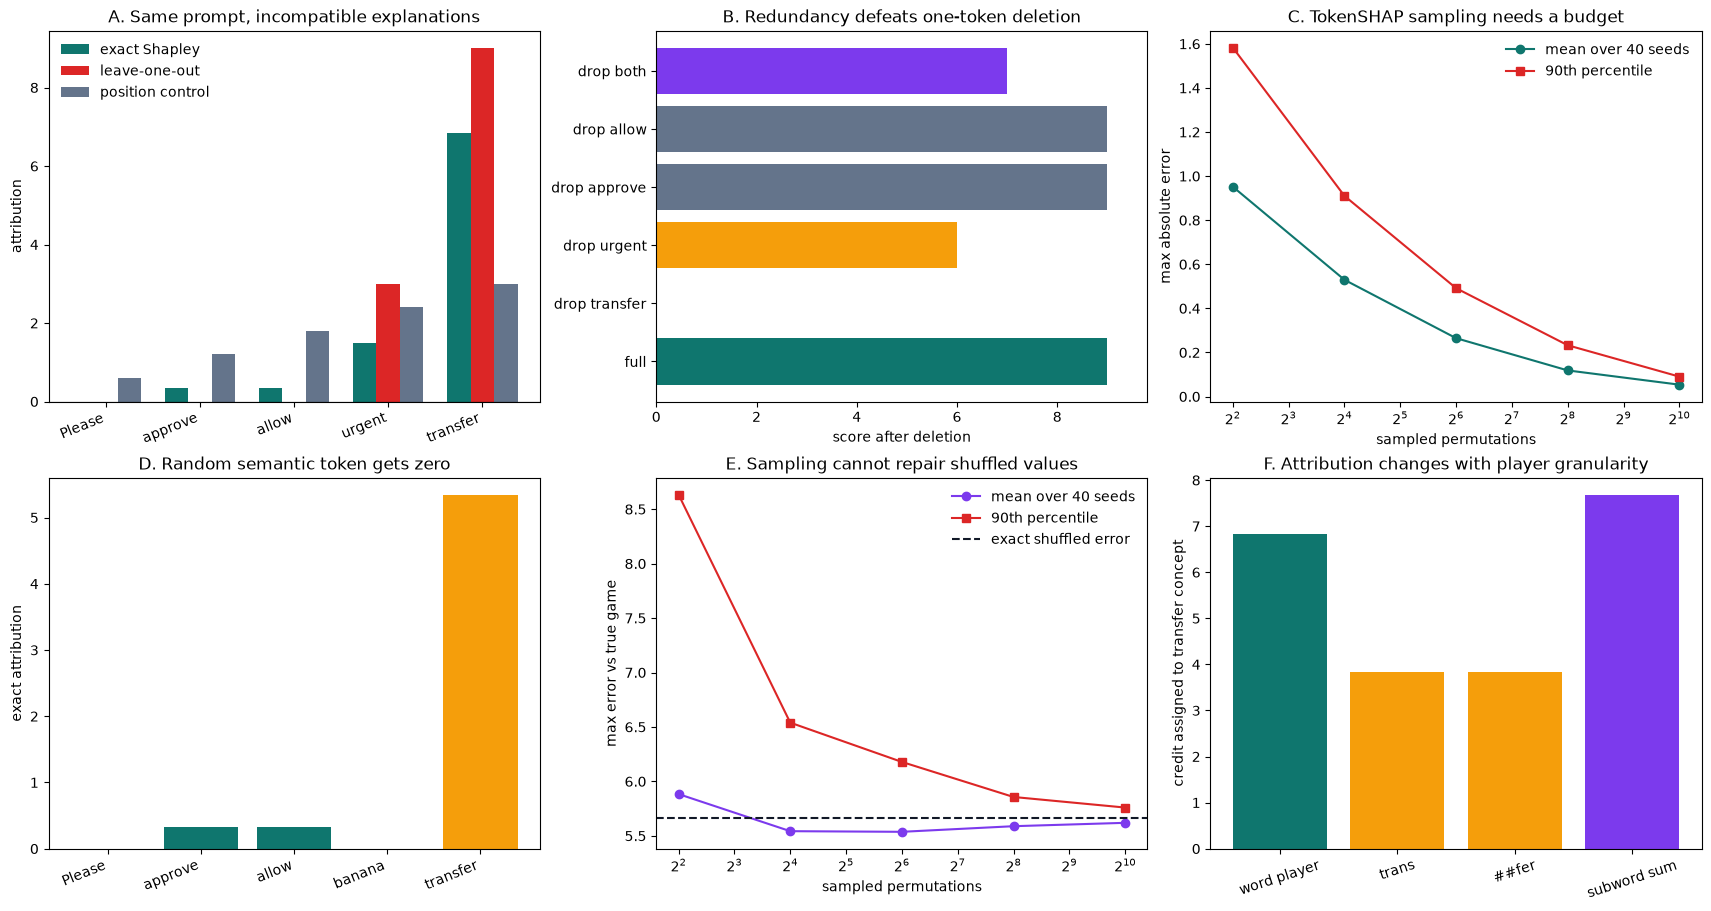

,token,exact_shapley,leave_one_out,position_control
0,Please,0.0000,0.0,0.6
1,approve,0.3333,0.0,1.2
2,allow,0.3333,0.0,1.8
3,urgent,1.5000,3.0,2.4
4,transfer,6.8333,9.0,3.0


Full-minus-mask score: 9.0 | Shapley sum: 9.0 | LOO sum: 12.0
 budget  mean_max_abs_error  p90_max_abs_error
      4              0.9521             1.5833
     16              0.5297             0.9104
     64              0.2648             0.4917
    256              0.1185             0.2327
   1024              0.0539             0.0904
Random-token vector: [0.0, 0.33333333333333337, 0.33333333333333337, 0.0, 5.333333333333334] 
Shuffled exact vector: [2.083333333333334, 2.416666666666667, 1.5, 1.8333333333333333, 1.166666666666667] 
Shuffled semantic max error: 5.666666666666667


In [11]:
if MAIN:
    values = token_coalition_values(TOKENS, structured_token_score)
if MAIN:
    exact = token_exact_shapley_values(values, num_players=len(TOKENS))
if MAIN:
    loo = leave_one_out_values(TOKENS, structured_token_score)
if MAIN:
    position = recency_position_control(9.0, len(TOKENS))
if MAIN:
    convergence = pd.DataFrame(sampling_convergence(
        values,
        num_players=len(TOKENS),
        budgets=(4, 16, 64, 256, 1024),
        seeds=tuple(range(40)),
    ))
if MAIN:
    random_exact = exact_token_shapley_values(RANDOM_CONTROL_TOKENS, structured_token_score)
if MAIN:
    shuffled_values = shuffle_coalition_values_within_sizes(
        values, num_players=len(TOKENS), seed=11
    )
if MAIN:
    shuffled_exact = token_exact_shapley_values(shuffled_values, num_players=len(TOKENS))
if MAIN:
    shuffled_convergence = pd.DataFrame(sampling_convergence(
        shuffled_values,
        num_players=len(TOKENS),
        budgets=(4, 16, 64, 256, 1024),
        seeds=tuple(range(40)),
        reference_values=exact,
    ))
if MAIN:

    deletions = {
        "full": structured_token_score(TOKENS),
        "drop transfer": structured_token_score(mask_tokens(TOKENS, {0, 1, 2, 3})),
        "drop urgent": structured_token_score(mask_tokens(TOKENS, {0, 1, 2, 4})),
        "drop approve": structured_token_score(mask_tokens(TOKENS, {0, 2, 3, 4})),
        "drop allow": structured_token_score(mask_tokens(TOKENS, {0, 1, 3, 4})),
        "drop both": structured_token_score(mask_tokens(TOKENS, {0, 3, 4})),
    }
if MAIN:

    split_values = token_coalition_values(SPLIT_TOKENS, split_token_score)
if MAIN:
    split_phi = token_exact_shapley_values(split_values, num_players=len(SPLIT_TOKENS))
groups = ((0,), (1,), (2,), (3,), (4, 5))
if MAIN:
    grouped_values = grouped_coalition_values(SPLIT_TOKENS, groups, split_token_score)
if MAIN:
    grouped_phi = token_exact_shapley_values(grouped_values, num_players=len(groups))
if MAIN:

    token_fig, token_axes = plt.subplots(2, 3, figsize=(17, 9), constrained_layout=True)
if MAIN:
    x = t.arange(len(TOKENS)).numpy()
width = 0.25
if MAIN:
    token_axes[0, 0].bar(x-width, exact.numpy(), width, label="exact Shapley", color="#0f766e")
if MAIN:
    token_axes[0, 0].bar(x, loo.numpy(), width, label="leave-one-out", color="#dc2626")
if MAIN:
    token_axes[0, 0].bar(x+width, position.numpy(), width, label="position control", color="#64748b")
if MAIN:
    token_axes[0, 0].axhline(0, color="black", linewidth=0.8)
if MAIN:
    token_axes[0, 0].set_xticks(x, TOKENS, rotation=22, ha="right")
if MAIN:
    token_axes[0, 0].set_ylabel("attribution")
if MAIN:
    token_axes[0, 0].set_title("A. Same prompt, incompatible explanations")
if MAIN:
    token_axes[0, 0].legend(frameon=False)
if MAIN:

    token_axes[0, 1].barh(list(deletions), list(deletions.values()), color=[
        "#0f766e", "#dc2626", "#f59e0b", "#64748b", "#64748b", "#7c3aed"
    ])
if MAIN:
    token_axes[0, 1].set_xlabel("score after deletion")
if MAIN:
    token_axes[0, 1].set_title("B. Redundancy defeats one-token deletion")
if MAIN:
    token_axes[0, 1].set_xlim(0, 9.8)
if MAIN:

    token_axes[0, 2].plot(
        convergence["budget"], convergence["mean_max_abs_error"],
        marker="o", label="mean over 40 seeds", color="#0f766e"
    )
if MAIN:
    token_axes[0, 2].plot(
        convergence["budget"], convergence["p90_max_abs_error"],
        marker="s", label="90th percentile", color="#dc2626"
    )
if MAIN:
    token_axes[0, 2].set_xscale("log", base=2)
if MAIN:
    token_axes[0, 2].set_xlabel("sampled permutations")
if MAIN:
    token_axes[0, 2].set_ylabel("max absolute error")
if MAIN:
    token_axes[0, 2].set_title("C. TokenSHAP sampling needs a budget")
if MAIN:
    token_axes[0, 2].legend(frameon=False)
if MAIN:

    random_x = t.arange(len(RANDOM_CONTROL_TOKENS)).numpy()
if MAIN:
    token_axes[1, 0].bar(random_x, random_exact.numpy(), color=[
        "#64748b", "#0f766e", "#0f766e", "#64748b", "#f59e0b"
    ])
if MAIN:
    token_axes[1, 0].set_xticks(random_x, RANDOM_CONTROL_TOKENS, rotation=22, ha="right")
if MAIN:
    token_axes[1, 0].set_ylabel("exact attribution")
if MAIN:
    token_axes[1, 0].set_title("D. Random semantic token gets zero")
if MAIN:

    token_axes[1, 1].plot(
        shuffled_convergence["budget"], shuffled_convergence["mean_max_abs_error"],
        marker="o", label="mean over 40 seeds", color="#7c3aed"
    )
if MAIN:
    token_axes[1, 1].plot(
        shuffled_convergence["budget"], shuffled_convergence["p90_max_abs_error"],
        marker="s", label="90th percentile", color="#dc2626"
    )
if MAIN:
    token_axes[1, 1].axhline(
        float((shuffled_exact-exact).abs().max()), color="#111827", linestyle="--",
        label="exact shuffled error"
    )
if MAIN:
    token_axes[1, 1].set_xscale("log", base=2)
if MAIN:
    token_axes[1, 1].set_xlabel("sampled permutations")
if MAIN:
    token_axes[1, 1].set_ylabel("max error vs true game")
if MAIN:
    token_axes[1, 1].set_title("E. Sampling cannot repair shuffled values")
if MAIN:
    token_axes[1, 1].legend(frameon=False)
if MAIN:

    tokenization_rows = {
        "word player": float(grouped_phi[-1]),
        "trans": float(split_phi[-2]),
        "##fer": float(split_phi[-1]),
        "subword sum": float(split_phi[-2:].sum()),
    }
if MAIN:
    token_axes[1, 2].bar(list(tokenization_rows), list(tokenization_rows.values()), color=[
        "#0f766e", "#f59e0b", "#f59e0b", "#7c3aed"
    ])
if MAIN:
    token_axes[1, 2].set_ylabel("credit assigned to transfer concept")
if MAIN:
    token_axes[1, 2].set_title("F. Attribution changes with player granularity")
if MAIN:
    token_axes[1, 2].tick_params(axis="x", rotation=18)
if MAIN:

    figure_path.parent.mkdir(parents=True, exist_ok=True)
if MAIN:
    token_fig.savefig(figure_path, dpi=180, bbox_inches="tight")
if MAIN:
    plt.show()
if MAIN:

    display(pd.DataFrame({
        "token": TOKENS,
        "exact_shapley": exact.tolist(),
        "leave_one_out": loo.tolist(),
        "position_control": position.tolist(),
    }).round(4))
if MAIN:
    print(f"Full-minus-mask score: 9.0 | Shapley sum: {exact.sum():.1f} | LOO sum: {loo.sum():.1f}")
if MAIN:
    print(convergence.round(4).to_string(index=False))
if MAIN:
    print(
        "Random-token vector:", random_exact.tolist(),
        "\nShuffled exact vector:", shuffled_exact.tolist(),
        "\nShuffled semantic max error:", float((shuffled_exact-exact).abs().max()),
    )

<details>
<summary>Interpretation - what is established?</summary>

<img src="../../exercises/part7_token_region_shap/media/tokenshap_exact_signature.png" width="960">

Exact Shapley assigns `0` to `Please`, `0.3333` to each redundant word, `1.5` to `urgent`, and
`6.8333` to the necessary `transfer` token, summing exactly to `9`. Leave-one-out misses both
redundant words and sums to `12`, because it double-counts the transfer interactions. The position
control sums to `9` but invents `0.6` credit for the distractor. At 1024 permutations the mean
maximum error over 40 seeds is about `0.0539` and the 90th percentile is about `0.0904`. These are
properties of this declared masked game, not intrinsic facts about the words.

Replacing `urgent` by random token `banana` gives it exactly `0` credit and lowers the score from
`9` to `6`. Shuffling values within coalition sizes preserves the empty/full endpoints but moves the
exact attribution to `[2.0833, 2.4167, 1.5, 1.8333, 1.1667]`, a maximum semantic error of `5.6667`.
Sampling converges to that wrong vector, not to the true game.

</details>

## Try It Yourself

Change the three payoff terms, sampling budget, or seed. Before running the cell, predict which
tokens move and whether leave-one-out still violates efficiency. Setting the redundant payoff to
zero should make `approve` and `allow` disappear from exact Shapley.

In [12]:
PLAY_BASE = 4.0
PLAY_REDUNDANT = 2.0
PLAY_URGENCY = 3.0
PLAY_SAMPLES = 128
PLAY_SEED = 11

def play_score(tokens):
    present = set(tokens)
    return float(("transfer" in present) * (
        PLAY_BASE
        + PLAY_REDUNDANT * (("approve" in present) or ("allow" in present))
        + PLAY_URGENCY * ("urgent" in present)
    ))
if MAIN:

    play_values = token_coalition_values(TOKENS, play_score)
if MAIN:
    play_exact = token_exact_shapley_values(play_values, num_players=len(TOKENS))
if MAIN:
    play_sampled = sampled_permutation_shapley_values(
        play_values,
        num_players=len(TOKENS),
        num_samples=PLAY_SAMPLES,
        seed=PLAY_SEED,
    )
if MAIN:
    display(pd.DataFrame({
        "token": TOKENS,
        "exact": play_exact.tolist(),
        "sampled": play_sampled.tolist(),
        "absolute_error": (play_exact-play_sampled).abs().tolist(),
    }).round(4))

,token,exact,sampled,absolute_error
0,Please,0.0000,0.0000,0.0000
1,approve,0.3333,0.4062,0.0729
2,allow,0.3333,0.4062,0.0729
3,urgent,1.5000,1.6641,0.1641
4,transfer,6.8333,6.5234,0.3099


## Bonus anomaly hunt - identical observations, different explanations

Suppose `approve` and `allow` are perfectly correlated in the data: they are always both present or
both absent. An OR game (redundancy) and an AND game (synergy) then agree on every observed
coalition. They disagree only on single-word coalitions created by masking. If the resulting Shapley
vectors differ, the data did not identify the explanation; the masking rule supplied the answer.

In [13]:
if MAIN:
    correlation_audit = correlated_pair_audit(
        TOKENS,
        lambda tokens: structured_token_score(tokens, redundant_mode="or"),
        lambda tokens: structured_token_score(tokens, redundant_mode="and"),
        pair=(1, 2),
    )
if MAIN:
    display(pd.DataFrame({
        "token": TOKENS,
        "OR redundancy": correlation_audit.redundancy_shapley.tolist(),
        "AND synergy": correlation_audit.synergy_shapley.tolist(),
        "difference": (
            correlation_audit.synergy_shapley-correlation_audit.redundancy_shapley
        ).tolist(),
    }).round(4))
if MAIN:
    print(
        "max difference on observed support:", correlation_audit.observed_max_abs_difference,
        "\nmax difference off manifold:", correlation_audit.off_manifold_max_abs_difference,
        "\nmax attribution difference:", correlation_audit.attribution_max_abs_difference,
        "\nidentified from observed support:", correlation_audit.identified_from_observed_support,
    )

,token,OR redundancy,AND synergy,difference
0,Please,0.0000,0.0000,0.0000
1,approve,0.3333,0.6667,0.3333
2,allow,0.3333,0.6667,0.3333
3,urgent,1.5000,1.5000,0.0000
4,transfer,6.8333,6.1667,-0.6667


max difference on observed support: 0.0 
max difference off manifold: 2.0 
max attribution difference: 0.666666666666667 
identified from observed support: False


<details>
<summary>Interpretation - why this is not a Shapley bug</summary>

The two games differ by `0` on every observed coalition but by as much as `2` off manifold. Their
token attributions differ by `2/3`. Shapley is exact for whichever value function you provide; it
cannot decide whether a masked, grammatically damaged prompt should behave like OR or AND. For real
models, report the masking operator, score, tokenizer, grouping, and sensitivity to plausible
alternatives.

</details>

In [14]:
token_reference_MAIN = False
if token_reference_MAIN:
    # %%
    """Reference solutions for [16.4] TokenSHAP and TokenShapley."""


import itertools
import math
import random
import sys
from collections.abc import Callable, Mapping, Sequence
from dataclasses import dataclass
from pathlib import Path

import torch as t

token_reference_chapter = "chapter16_shapley_attribution_baselines"
if token_reference_MAIN:
    token_reference_root_dir = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / token_reference_chapter).exists())
if token_reference_MAIN:
    if str(token_reference_root_dir) not in sys.path:
        sys.path.append(str(token_reference_root_dir))

token_reference_MAIN = False
token_reference_MASK_TOKEN = "[MASK]"
token_reference_LAB_TOKENS = ("Please", "approve", "allow", "urgent", "transfer")
token_reference_RANDOM_CONTROL_TOKENS = ("Please", "approve", "allow", "banana", "transfer")
token_reference_SPLIT_TOKENS = ("Please", "approve", "allow", "urgent", "trans", "##fer")

# This separate four-token game preserves the existing release-only CUDA contract.
token_reference_TOKENS = ("The", "capital", "is", "Paris")
token_reference_TOKEN_MODEL_SEED = 1640
token_reference_TOKEN_MODEL_EMBED_DIM = 32
token_reference_TOKEN_MODEL_HIDDEN_DIM = 96
token_reference_TOKEN_MODEL_STEPS = 1200
token_reference_TOKEN_MODEL_LR = 2e-2
token_reference_TOKEN_MODEL_FIT_MSE_MAX = 1e-10
token_reference_TOKEN_MODEL_EXACT_SHAPLEY_ERROR_MAX = 1e-5
token_reference_TOKEN_MODEL_SAMPLED_ERROR_MAX = 0.1
token_reference_TOKEN_MODEL_SHUFFLED_ERROR_MIN = 1.0

Coalition = frozenset[int]


@dataclass(frozen=True)
class token_reference_TokenShapleySamplingReport:
    tokens: tuple[str, ...]
    exact_values: t.Tensor
    sampled_values: t.Tensor
    max_abs_error: float
    top_token: str
    sampled_top_token: str
    rank_matches: bool
    approximates_exact: bool


@dataclass(frozen=True)
class token_reference_TokenBaselineReport:
    full_score: float
    baseline_score: float
    total_delta: float
    shapley_sum: float
    efficiency_error: float
    satisfies_efficiency: bool


@dataclass(frozen=True)
class token_reference_CorrelatedPairAudit:
    observed_max_abs_difference: float
    off_manifold_max_abs_difference: float
    redundancy_shapley: t.Tensor
    synergy_shapley: t.Tensor
    attribution_max_abs_difference: float
    identified_from_observed_support: bool


def token_reference_all_coalitions(num_players: int) -> tuple[Coalition, ...]:
    """Enumerate the powerset in increasing coalition-size order."""
    if num_players <= 0:
        raise ValueError("num_players must be positive.")
    players = range(num_players)
    return tuple(
        frozenset(group)
        for size in range(num_players + 1)
        for group in itertools.combinations(players, size)
    )


def token_reference_mask_tokens(
    tokens: Sequence[str],
    coalition: Coalition | Sequence[int],
    *,
    mask_token: str = token_reference_MASK_TOKEN,
) -> tuple[str, ...]:
    """Keep coalition members and mask every other token position."""
    token_tuple = tuple(tokens)
    if not token_tuple:
        raise ValueError("tokens must be nonempty.")
    keep = frozenset(coalition)
    if not keep.issubset(range(len(token_tuple))):
        raise ValueError("coalition contains an out-of-range token position.")
    return tuple(token if index in keep else mask_token for index, token in enumerate(token_tuple))


def token_reference_structured_token_score(
    tokens: Sequence[str],
    *,
    redundant_mode: str = "or",
) -> float:
    """Exact game with a necessary token, a redundant pair, and an interaction."""
    if redundant_mode not in {"or", "and"}:
        raise ValueError("redundant_mode must be 'or' or 'and'.")
    present = set(tokens)
    transfer = "transfer" in present
    approve = "approve" in present
    allow = "allow" in present
    urgent = "urgent" in present
    redundant_gate = (approve or allow) if redundant_mode == "or" else (approve and allow)
    return float(transfer * (4.0 + 2.0 * redundant_gate + 3.0 * urgent))


def token_reference_split_token_score(tokens: Sequence[str], *, redundant_mode: str = "or") -> float:
    """Apply the same semantic rule when transfer is split into two required pieces."""
    present = set(tokens)
    rebuilt = list(tokens)
    if "trans" in present and "##fer" in present:
        rebuilt.append("transfer")
    return token_reference_structured_token_score(rebuilt, redundant_mode=redundant_mode)


def token_reference_token_coalition_values(
    tokens: Sequence[str],
    score_fn: Callable[[tuple[str, ...]], float],
    *,
    mask_token: str = token_reference_MASK_TOKEN,
) -> dict[Coalition, float]:
    """Evaluate a score on every position-preserving masked coalition."""
    token_tuple = tuple(tokens)
    if not token_tuple:
        raise ValueError("tokens must be nonempty.")
    return {
        coalition: float(score_fn(token_reference_mask_tokens(token_tuple, coalition, mask_token=mask_token)))
        for coalition in token_reference_all_coalitions(len(token_tuple))
    }


def token_reference_normalize_coalition_values(
    coalition_values: Mapping[Coalition | tuple[int, ...], float],
    *,
    num_players: int,
) -> dict[Coalition, float]:
    """Normalize keys and require one value for every valid coalition."""
    values = {frozenset(key): float(value) for key, value in coalition_values.items()}
    expected = set(token_reference_all_coalitions(num_players))
    missing = expected - set(values)
    extra = set(values) - expected
    if missing or extra:
        raise ValueError(
            f"coalition table must be complete: missing={len(missing)}, extra={len(extra)}."
        )
    return values


def token_reference_exact_shapley_values(
    coalition_values: Mapping[Coalition | tuple[int, ...], float],
    *,
    num_players: int,
) -> t.Tensor:
    """Compute exact Shapley values from a complete finite game."""
    values = token_reference_normalize_coalition_values(coalition_values, num_players=num_players)
    result = t.zeros(num_players, dtype=t.float64)
    denominator = math.factorial(num_players)
    for player in range(num_players):
        others = [index for index in range(num_players) if index != player]
        for size in range(num_players):
            weight = math.factorial(size) * math.factorial(num_players - size - 1) / denominator
            for members in itertools.combinations(others, size):
                coalition = frozenset(members)
                result[player] += weight * (values[coalition | {player}] - values[coalition])
    return result


def token_reference_exact_token_shapley_values(
    tokens: Sequence[str],
    score_fn: Callable[[tuple[str, ...]], float],
    *,
    mask_token: str = token_reference_MASK_TOKEN,
) -> t.Tensor:
    token_tuple = tuple(tokens)
    values = token_reference_token_coalition_values(token_tuple, score_fn, mask_token=mask_token)
    return token_reference_exact_shapley_values(values, num_players=len(token_tuple))


def token_reference_sampled_permutation_shapley_values(
    coalition_values: Mapping[Coalition | tuple[int, ...], float],
    *,
    num_players: int,
    num_samples: int,
    seed: int = 0,
) -> t.Tensor:
    """Estimate Shapley values from marginal contributions along random orders."""
    if num_samples <= 0:
        raise ValueError("num_samples must be positive.")
    values = token_reference_normalize_coalition_values(coalition_values, num_players=num_players)
    rng = random.Random(seed)
    totals = t.zeros(num_players, dtype=t.float64)
    players = tuple(range(num_players))
    for _ in range(num_samples):
        coalition: Coalition = frozenset()
        for player in rng.sample(players, k=num_players):
            with_player = coalition | {player}
            totals[player] += values[with_player] - values[coalition]
            coalition = with_player
    return totals / num_samples


def token_reference_sampled_token_shapley_values(
    tokens: Sequence[str],
    score_fn: Callable[[tuple[str, ...]], float],
    *,
    mask_token: str = token_reference_MASK_TOKEN,
    num_samples: int = 256,
    seed: int = 0,
) -> t.Tensor:
    token_tuple = tuple(tokens)
    values = token_reference_token_coalition_values(token_tuple, score_fn, mask_token=mask_token)
    return token_reference_sampled_permutation_shapley_values(
        values, num_players=len(token_tuple), num_samples=num_samples, seed=seed
    )


def token_reference_shuffle_coalition_values_within_sizes(
    coalition_values: Mapping[Coalition | tuple[int, ...], float],
    *,
    num_players: int,
    seed: int = 0,
) -> dict[Coalition, float]:
    """Shuffle values among equally sized masks while preserving both endpoints."""
    values = token_reference_normalize_coalition_values(coalition_values, num_players=num_players)
    rng = random.Random(seed)
    shuffled: dict[Coalition, float] = {}
    for size in range(num_players + 1):
        coalitions = [coalition for coalition in token_reference_all_coalitions(num_players) if len(coalition) == size]
        bucket = [values[coalition] for coalition in coalitions]
        rng.shuffle(bucket)
        shuffled.update(zip(coalitions, bucket, strict=True))
    return shuffled


def token_reference_leave_one_out_values(
    tokens: Sequence[str],
    score_fn: Callable[[tuple[str, ...]], float],
    *,
    mask_token: str = token_reference_MASK_TOKEN,
) -> t.Tensor:
    """Compute each token's local full-prompt deletion effect."""
    token_tuple = tuple(tokens)
    full_score = float(score_fn(token_tuple))
    result = []
    for player in range(len(token_tuple)):
        kept = frozenset(index for index in range(len(token_tuple)) if index != player)
        result.append(full_score - float(score_fn(token_reference_mask_tokens(token_tuple, kept, mask_token=mask_token))))
    return t.tensor(result, dtype=t.float64)


def token_reference_recency_position_control(total_delta: float, num_players: int) -> t.Tensor:
    """Allocate credit by position alone while still satisfying efficiency."""
    if num_players <= 0:
        raise ValueError("num_players must be positive.")
    weights = t.arange(1, num_players + 1, dtype=t.float64)
    return float(total_delta) * weights / weights.sum()


def token_reference_discrete_pair_interaction(
    coalition_values: Mapping[Coalition | tuple[int, ...], float],
    pair: tuple[int, int],
    *,
    context: Coalition | Sequence[int] = frozenset(),
    num_players: int,
) -> float:
    """Return a pair's finite second difference in one coalition context."""
    i, j = pair
    if i == j or not {i, j}.issubset(range(num_players)):
        raise ValueError("pair must contain two distinct valid players.")
    base = frozenset(context)
    if base & {i, j}:
        raise ValueError("context must exclude both members of the pair.")
    values = token_reference_normalize_coalition_values(coalition_values, num_players=num_players)
    return values[base | {i, j}] - values[base | {i}] - values[base | {j}] + values[base]


def token_reference_grouped_coalition_values(
    tokens: Sequence[str],
    groups: Sequence[Sequence[int]],
    score_fn: Callable[[tuple[str, ...]], float],
    *,
    mask_token: str = token_reference_MASK_TOKEN,
) -> dict[Coalition, float]:
    """Treat declared groups of token positions as the Shapley players."""
    token_tuple = tuple(tokens)
    normalized_groups = tuple(frozenset(group) for group in groups)
    flattened = [position for group in normalized_groups for position in group]
    if sorted(flattened) != list(range(len(token_tuple))):
        raise ValueError("groups must partition every token position exactly once.")
    values: dict[Coalition, float] = {}
    for coalition in token_reference_all_coalitions(len(normalized_groups)):
        kept = (
            frozenset().union(*(normalized_groups[index] for index in coalition))
            if coalition
            else frozenset()
        )
        values[coalition] = float(score_fn(token_reference_mask_tokens(token_tuple, kept, mask_token=mask_token)))
    return values


def token_reference_correlated_pair_audit(
    tokens: Sequence[str],
    redundancy_score_fn: Callable[[tuple[str, ...]], float],
    synergy_score_fn: Callable[[tuple[str, ...]], float],
    *,
    pair: tuple[int, int],
    mask_token: str = token_reference_MASK_TOKEN,
) -> token_reference_CorrelatedPairAudit:
    """Test whether correlated support identifies the off-manifold game."""
    token_tuple = tuple(tokens)
    redundancy_values = token_reference_token_coalition_values(token_tuple, redundancy_score_fn, mask_token=mask_token)
    synergy_values = token_reference_token_coalition_values(token_tuple, synergy_score_fn, mask_token=mask_token)
    i, j = pair
    observed = [c for c in token_reference_all_coalitions(len(token_tuple)) if (i in c) == (j in c)]
    off_manifold = [c for c in token_reference_all_coalitions(len(token_tuple)) if (i in c) != (j in c)]
    observed_difference = max(abs(redundancy_values[c] - synergy_values[c]) for c in observed)
    off_manifold_difference = max(abs(redundancy_values[c] - synergy_values[c]) for c in off_manifold)
    redundancy_shapley = token_reference_exact_shapley_values(redundancy_values, num_players=len(token_tuple))
    synergy_shapley = token_reference_exact_shapley_values(synergy_values, num_players=len(token_tuple))
    attribution_difference = float((redundancy_shapley - synergy_shapley).abs().max().item())
    return token_reference_CorrelatedPairAudit(
        observed_difference,
        off_manifold_difference,
        redundancy_shapley,
        synergy_shapley,
        attribution_difference,
        observed_difference > 0.0 or attribution_difference == 0.0,
    )


def token_reference_sampling_convergence(
    coalition_values: Mapping[Coalition | tuple[int, ...], float],
    *,
    num_players: int,
    budgets: Sequence[int],
    seeds: Sequence[int],
    reference_values: t.Tensor | None = None,
) -> list[dict[str, float | int]]:
    """Summarize Monte Carlo maximum attribution error over seeds."""
    if not budgets or not seeds:
        raise ValueError("budgets and seeds must be nonempty.")
    exact = (
        token_reference_exact_shapley_values(coalition_values, num_players=num_players)
        if reference_values is None
        else t.as_tensor(reference_values, dtype=t.float64)
    )
    if exact.shape != (num_players,):
        raise ValueError(f"reference_values must have shape ({num_players},).")
    rows = []
    for budget in budgets:
        errors = t.tensor(
            [
                float(
                    (
                        token_reference_sampled_permutation_shapley_values(
                            coalition_values,
                            num_players=num_players,
                            num_samples=int(budget),
                            seed=int(seed),
                        )
                        - exact
                    ).abs().max().item()
                )
                for seed in seeds
            ],
            dtype=t.float64,
        )
        rows.append(
            {
                "budget": int(budget),
                "mean_max_abs_error": float(errors.mean().item()),
                "p90_max_abs_error": float(t.quantile(errors, 0.9).item()),
            }
        )
    return rows


def token_reference_token_baseline_report(
    tokens: Sequence[str],
    score_fn: Callable[[tuple[str, ...]], float],
    *,
    mask_token: str = token_reference_MASK_TOKEN,
    tolerance: float = 1e-9,
) -> token_reference_TokenBaselineReport:
    token_tuple = tuple(tokens)
    exact = token_reference_exact_token_shapley_values(token_tuple, score_fn, mask_token=mask_token)
    full_score = float(score_fn(token_tuple))
    baseline_score = float(score_fn(tuple(mask_token for _ in token_tuple)))
    total_delta = full_score - baseline_score
    shapley_sum = float(exact.sum().item())
    error = abs(shapley_sum - total_delta)
    return token_reference_TokenBaselineReport(full_score, baseline_score, total_delta, shapley_sum, error, error <= tolerance)


def token_reference_token_shapley_sampling_report(
    tokens: Sequence[str],
    score_fn: Callable[[tuple[str, ...]], float],
    *,
    mask_token: str = token_reference_MASK_TOKEN,
    num_samples: int = 256,
    seed: int = 0,
    tolerance: float = 0.15,
) -> token_reference_TokenShapleySamplingReport:
    token_tuple = tuple(tokens)
    exact = token_reference_exact_token_shapley_values(token_tuple, score_fn, mask_token=mask_token)
    sampled = token_reference_sampled_token_shapley_values(
        token_tuple, score_fn, mask_token=mask_token, num_samples=num_samples, seed=seed
    )
    max_error = float((exact - sampled).abs().max().item())
    top = int(exact.argmax().item())
    sampled_top = int(sampled.argmax().item())
    return token_reference_TokenShapleySamplingReport(
        token_tuple, exact, sampled, max_error, token_tuple[top], token_tuple[sampled_top],
        top == sampled_top, max_error <= tolerance,
    )


# Release preflight: retained for the serialized course contract, not taught as
# the main result. It trains a finite scorer rather than claiming LLM validity.
def token_reference_keyword_interaction_token_score(
    tokens: Sequence[str],
    *,
    target_token: str = "Paris",
    context_token: str = "capital",
    target_weight: float = 1.0,
    interaction_weight: float = 2.0,
) -> float:
    present = set(tokens)
    score = target_weight if target_token in present else 0.0
    if target_token in present and context_token in present:
        score += interaction_weight
    return float(score)


def token_reference__tensor_report(report) -> dict:
    result = report.__dict__.copy()
    for key, value in list(result.items()):
        if hasattr(value, "tolist"):
            result[key] = value.tolist()
    return result


def token_reference_run_smoke_test(cpu: bool = True) -> dict:
    _ = cpu
    values = token_reference_token_coalition_values(token_reference_TOKENS, token_reference_keyword_interaction_token_score)
    exact = token_reference_exact_token_shapley_values(token_reference_TOKENS, token_reference_keyword_interaction_token_score)
    sampled = token_reference_token_shapley_sampling_report(
        token_reference_TOKENS, token_reference_keyword_interaction_token_score, num_samples=512, seed=0, tolerance=0.1
    )
    return {
        "coalitions": {
            "empty": values[frozenset()],
            "target_only": values[frozenset({3})],
            "context_and_target": values[frozenset({1, 3})],
        },
        "exact": {
            "tokens": list(token_reference_TOKENS),
            "exact_values": exact.tolist(),
            "baseline": token_reference_token_baseline_report(token_reference_TOKENS, token_reference_keyword_interaction_token_score).__dict__,
        },
        "sampled": token_reference__tensor_report(sampled),
    }


def token_reference_run_gpu_test(max_vram_gb: float = 24.0) -> dict:
    if not t.cuda.is_available():
        raise RuntimeError("16.4 GPU preflight requires CUDA; no CPU fallback is accepted.")
    return token_reference_run_neural_token_shapley_preflight(max_vram_gb=max_vram_gb)


class token_reference__TinyTokenScorer(t.nn.Module):
    def __init__(self, vocab_size: int) -> None:
        super().__init__()
        self.embedding = t.nn.Embedding(vocab_size, token_reference_TOKEN_MODEL_EMBED_DIM)
        self.net = t.nn.Sequential(
            t.nn.Linear(len(token_reference_TOKENS) * token_reference_TOKEN_MODEL_EMBED_DIM, token_reference_TOKEN_MODEL_HIDDEN_DIM),
            t.nn.GELU(),
            t.nn.Linear(token_reference_TOKEN_MODEL_HIDDEN_DIM, token_reference_TOKEN_MODEL_HIDDEN_DIM),
            t.nn.GELU(),
            t.nn.Linear(token_reference_TOKEN_MODEL_HIDDEN_DIM, 1),
        )

    def forward(self, token_ids: t.Tensor) -> t.Tensor:
        return self.net(self.embedding(token_ids).flatten(start_dim=1))


def token_reference__token_vocab() -> dict[str, int]:
    return {token_reference_MASK_TOKEN: 0, **{token: index + 1 for index, token in enumerate(token_reference_TOKENS)}}


def token_reference__token_training_table(device: t.device) -> tuple[t.Tensor, t.Tensor, dict[str, int]]:
    vocab = token_reference__token_vocab()
    rows, targets = [], []
    for coalition in token_reference_all_coalitions(len(token_reference_TOKENS)):
        masked = token_reference_mask_tokens(token_reference_TOKENS, coalition)
        rows.append([vocab[token] for token in masked])
        targets.append(token_reference_keyword_interaction_token_score(masked))
    return (
        t.tensor(rows, device=device, dtype=t.long),
        t.tensor(targets, device=device, dtype=t.float32).unsqueeze(-1),
        vocab,
    )


def token_reference__train_token_scorer(
    token_ids: t.Tensor,
    targets: t.Tensor,
    *,
    vocab_size: int,
) -> tuple[token_reference__TinyTokenScorer, float, float]:
    t.manual_seed(token_reference_TOKEN_MODEL_SEED)
    t.cuda.manual_seed_all(token_reference_TOKEN_MODEL_SEED)
    model = token_reference__TinyTokenScorer(vocab_size=vocab_size).to(token_ids.device)
    optimizer = t.optim.AdamW(model.parameters(), lr=token_reference_TOKEN_MODEL_LR, weight_decay=0.0)
    for _ in range(token_reference_TOKEN_MODEL_STEPS):
        prediction = model(token_ids)
        loss = ((prediction - targets) ** 2).mean()
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    with t.no_grad():
        residual = model(token_ids) - targets
    return model, float((residual**2).mean().item()), float(residual.abs().max().item())


def token_reference__model_score_fn(model: token_reference__TinyTokenScorer, vocab: dict[str, int]):
    def score(tokens: tuple[str, ...]) -> float:
        ids = t.tensor(
            [[vocab[token] for token in tokens]],
            device=next(model.parameters()).device,
            dtype=t.long,
        )
        with t.no_grad():
            return float(model(ids).item())
    return score


def token_reference_run_neural_token_shapley_preflight(max_vram_gb: float = 24.0) -> dict:
    device = t.device("cuda")
    t.cuda.reset_peak_memory_stats()
    token_ids, targets, vocab = token_reference__token_training_table(device)
    model, fit_mse, fit_max_abs_error = token_reference__train_token_scorer(token_ids, targets, vocab_size=len(vocab))
    model_score = token_reference__model_score_fn(model, vocab)
    exact_values = token_reference_exact_token_shapley_values(token_reference_TOKENS, model_score)
    true_exact = token_reference_exact_token_shapley_values(token_reference_TOKENS, token_reference_keyword_interaction_token_score)
    exact_error = float((exact_values - true_exact).abs().max().item())
    sampled_report = token_reference_token_shapley_sampling_report(
        token_reference_TOKENS, model_score, num_samples=512, seed=0, tolerance=token_reference_TOKEN_MODEL_SAMPLED_ERROR_MAX
    )
    baseline = token_reference_token_baseline_report(token_reference_TOKENS, model_score)

    generator = t.Generator(device=device).manual_seed(token_reference_TOKEN_MODEL_SEED)
    shuffled = targets[t.randperm(targets.shape[0], device=device, generator=generator)]
    shuffled_model, shuffled_fit_mse, _ = token_reference__train_token_scorer(token_ids, shuffled, vocab_size=len(vocab))
    shuffled_exact = token_reference_exact_token_shapley_values(token_reference_TOKENS, token_reference__model_score_fn(shuffled_model, vocab))
    shuffled_error = float((shuffled_exact - true_exact).abs().max().item())
    t.cuda.synchronize()
    peak_vram_gb = t.cuda.max_memory_allocated() / 1024**3
    passed = (
        fit_mse <= token_reference_TOKEN_MODEL_FIT_MSE_MAX
        and exact_error <= token_reference_TOKEN_MODEL_EXACT_SHAPLEY_ERROR_MAX
        and sampled_report.approximates_exact
        and sampled_report.rank_matches
        and sampled_report.top_token == "Paris"
        and baseline.satisfies_efficiency
        and shuffled_error >= token_reference_TOKEN_MODEL_SHUFFLED_ERROR_MIN
        and peak_vram_gb <= max_vram_gb
    )
    return {
        "preflight_passed": passed,
        "cuda_available": True,
        "device": t.cuda.get_device_name(0),
        "model_family": "cuda_trained_tiny_token_scorer_mlp",
        "token_count": len(token_reference_TOKENS),
        "coalition_count": 2 ** len(token_reference_TOKENS),
        "training_example_count": int(token_ids.shape[0]),
        "training_steps": token_reference_TOKEN_MODEL_STEPS,
        "fit_mse": fit_mse,
        "fit_max_abs_error": fit_max_abs_error,
        "true_exact_values": true_exact.tolist(),
        "model_exact_values": exact_values.tolist(),
        "exact_shapley_max_abs_error": exact_error,
        "sampled_values": sampled_report.sampled_values.tolist(),
        "sampled_max_abs_error": sampled_report.max_abs_error,
        "sampled_rank_matches": sampled_report.rank_matches,
        "sampled_top_token": sampled_report.sampled_top_token,
        "top_token": sampled_report.top_token,
        "baseline_efficiency_error": baseline.efficiency_error,
        "satisfies_efficiency": baseline.satisfies_efficiency,
        "shuffled_control_fit_mse": shuffled_fit_mse,
        "shuffled_control_exact_values": shuffled_exact.tolist(),
        "shuffled_control_error": shuffled_error,
        "shuffled_control_rejected": shuffled_error >= token_reference_TOKEN_MODEL_SHUFFLED_ERROR_MIN,
        "peak_vram_gb": peak_vram_gb,
        "within_vram_budget": peak_vram_gb <= max_vram_gb,
        "full_path": "Finite CUDA scorer preflight; the exact learner organism remains the main result.",
    }


def token_reference_run_full_experiment(max_vram_gb: float = 24.0) -> dict:
    return token_reference_run_gpu_test(max_vram_gb=max_vram_gb)


if token_reference_MAIN:
    token_reference_values = token_reference_token_coalition_values(token_reference_LAB_TOKENS, token_reference_structured_token_score)
    print(token_reference_exact_shapley_values(token_reference_values, num_players=len(token_reference_LAB_TOKENS)))

In [15]:
token_reference = SimpleNamespace(
    TokenShapleySamplingReport=token_reference_TokenShapleySamplingReport,
    TokenBaselineReport=token_reference_TokenBaselineReport,
    CorrelatedPairAudit=token_reference_CorrelatedPairAudit,
    all_coalitions=token_reference_all_coalitions,
    mask_tokens=token_reference_mask_tokens,
    structured_token_score=token_reference_structured_token_score,
    split_token_score=token_reference_split_token_score,
    token_coalition_values=token_reference_token_coalition_values,
    normalize_coalition_values=token_reference_normalize_coalition_values,
    exact_shapley_values=token_reference_exact_shapley_values,
    exact_token_shapley_values=token_reference_exact_token_shapley_values,
    sampled_permutation_shapley_values=token_reference_sampled_permutation_shapley_values,
    sampled_token_shapley_values=token_reference_sampled_token_shapley_values,
    shuffle_coalition_values_within_sizes=token_reference_shuffle_coalition_values_within_sizes,
    leave_one_out_values=token_reference_leave_one_out_values,
    recency_position_control=token_reference_recency_position_control,
    discrete_pair_interaction=token_reference_discrete_pair_interaction,
    grouped_coalition_values=token_reference_grouped_coalition_values,
    correlated_pair_audit=token_reference_correlated_pair_audit,
    sampling_convergence=token_reference_sampling_convergence,
    token_baseline_report=token_reference_token_baseline_report,
    token_shapley_sampling_report=token_reference_token_shapley_sampling_report,
    keyword_interaction_token_score=token_reference_keyword_interaction_token_score,
    _tensor_report=token_reference__tensor_report,
    run_smoke_test=token_reference_run_smoke_test,
    run_gpu_test=token_reference_run_gpu_test,
    _TinyTokenScorer=token_reference__TinyTokenScorer,
    _token_vocab=token_reference__token_vocab,
    _token_training_table=token_reference__token_training_table,
    _train_token_scorer=token_reference__train_token_scorer,
    _model_score_fn=token_reference__model_score_fn,
    run_neural_token_shapley_preflight=token_reference_run_neural_token_shapley_preflight,
    run_full_experiment=token_reference_run_full_experiment,
)

In [16]:
if MAIN:
    verification_report_path = section_dir / "verification_report.json"

def token_run_gpu_test(max_vram_gb: float = 24.0) -> dict:
    run = token_reference.run_gpu_test
    return run(max_vram_gb=max_vram_gb)

def token_run_full_experiment(max_vram_gb: float = 24.0) -> dict:
    run = token_reference.run_full_experiment
    return run(max_vram_gb=max_vram_gb)

## From this exact game to TokenSHAP

[TokenSHAP (Horovicz and Goldshmidt, NLP4Science
2024)](https://aclanthology.org/2024.nlp4science-1.1/) adapts Shapley attribution to prompt tokens
or substrings and uses Monte Carlo sampling because exact enumeration is exponential. The original
[SHAP paper (Lundberg and Lee, NeurIPS
2017)](https://proceedings.neurips.cc/paper/2017/hash/8a20a8621978632d76c43dfd28b67767-Abstract.html)
explains the broader additive feature-attribution framework.

This notebook deliberately fixes a scalar score and an exact masking game. A real LLM study must
additionally justify whether it attributes a target-token logit, sequence log-probability, task
reward, response similarity, or another quantity. Those choices define different games.

## Limitations

- Exact enumeration costs `2**n` score evaluations; permutation sampling reduces cost but adds
variance, as the seed distribution shows.
- Mask tokens, deletion, infilling, and conditional sampling define different counterfactuals.
- Subword tokenization changes the player set; grouping is a scientific choice, not formatting.
- Perfectly correlated tokens leave off-manifold coalition values unidentified.
- The finite release-only CUDA preflight in `solutions.py` validates implementation plumbing only. It does
not establish faithful explanations for an LLM, generation behavior, or human reasoning.

A defensible real-model follow-up should preregister the score and masking rule, repeat the analysis
across tokenizers and groupings, include deletion/insertion faithfulness curves, and audit whether
sampled coalitions remain linguistically meaningful.

# 2️⃣ Modality and region games

> ##### Learning Objectives
>
> - Enumerate finite games and test efficiency before attributing model scores.
> - Keep modality replacement and object/background/OCR replacement as separate estimands.
> - Inspect every rendered coalition and caption control before interpreting the pinned CLIP result.

### [16.5] VLM Modality and Region SHAP

## Core Question

When the CLIP score for "a red square" rises, which counterfactual replacement supplied the
evidence?

**By the end of this notebook, you will have shown that exact Shapley attribution on a pinned CLIP
red-square score assigns more value to the target object than to background or OCR controls, while a
positive image-text interaction survives an explicit target-vs-distractor check.**

You will answer it twice: first on games where the answer is known exactly, then on all rendered
coalitions scored by a real pinned CLIP checkpoint.

## Learning goals

You will:

- enumerate and validate complete finite coalition games;
- derive exact Shapley values from weighted marginal contributions;
- separate additive modality evidence from image-text interaction;
- render object, background, and OCR interventions you can inspect pixel by pixel;
- require efficiency, object-vs-control margin, and target-vs-distractor margin before accepting a result;
- state exactly what input-level Shapley does and does not reveal about a VLM mechanism.

## Cold Open: one score, several explanations

A high score for “a red square” might come from the red object, the word `RED`, a background
artifact, the caption, or an interaction among them. A heatmap cannot distinguish these stories by
appearance alone. We will define the players and every counterfactual image first, then let exact
Shapley average each player’s marginal effect over every context.

## Setup

The token-position exercises run on CPU. The CLIP signature needs a CUDA GPU: the exercises take about 20 minutes, and scoring the cached CLIP coalitions takes under a minute.

In [17]:
from collections.abc import Callable, Mapping
from dataclasses import dataclass
from pathlib import Path
import itertools
import math
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch as t
from IPython.display import display

chapter = "chapter16_shapley_attribution_baselines"
if MAIN:
    region_root_dir = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / chapter).exists())
if MAIN:
    if str(region_root_dir) not in sys.path:
        sys.path.append(str(region_root_dir))

from chapter16_shapley_attribution_baselines.exercises.part5_vlm_modality_region_shap import tests as region_tests
if MAIN:


    assets_dir = region_root_dir / chapter / "exercises" / "part7_token_region_shap" / "media"
if MAIN:
    assets_dir.mkdir(parents=True, exist_ok=True)
Coalition = frozenset[int]
MAIN = __name__ == "__main__"
if MAIN:

    plt.style.use("seaborn-v0_8-whitegrid")
COLORS = {
    "red": "#C73E3A",
    "teal": "#147D7E",
    "gold": "#D49A18",
    "blue": "#3B6EA8",
    "gray": "#7A7F87",
    "ink": "#20242A",
}

In [18]:
@dataclass(frozen=True)
class ShapleyEfficiencyReport:
    shapley_sum: float
    total_value_delta: float
    efficiency_error: float
    satisfies_efficiency: bool


@dataclass(frozen=True)
class VLMModalitySHAPReport:
    modality_values: t.Tensor
    baseline_score: float
    image_only_score: float
    text_only_score: float
    full_score: float
    synergy: float
    detects_synergy: bool
    satisfies_efficiency: bool


@dataclass(frozen=True)
class VLMRegionSHAPReport:
    region_values: t.Tensor
    region_names: tuple[str, ...]
    target_region: str
    target_value: float
    max_background_value: float
    localizes_target: bool
    satisfies_efficiency: bool

## 1. Exact finite games

For players $N=\{0,\ldots,n-1\}$, a game assigns a value $v(S)$ to every coalition $S\subseteq N$.
Exact Shapley attribution is only meaningful here if the table really contains all $2^n$ coalitions.
This gives us a cheap first checkpoint before any model is loaded.

### Exercise - enumerate and validate every coalition

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-20 minutes on this exercise.
> ```

> **Difficulty:** medium
> **Importance:** high
> **Suggested time:** 10 minutes

Implement `all_coalitions` and `normalize_coalition_values`. The latter must reject incomplete games
instead of silently turning a missing intervention into a zero.

<details>
<summary>Expected output</summary>

```text
All tests in `test_all_coalitions_and_normalization` passed!
```

</details>

<details>
<summary>Help - common bug</summary>

Iterate subset sizes from `0` through `num_players`; `itertools.combinations` gives each subset
once. Normalize keys to `frozenset` before comparing with the expected set.

</details>

<details>
<summary>Common bugs</summary>

- Starting at subset size one and losing the baseline.
- Stopping before the full coalition.
- Checking only the number of entries, which misses duplicated or invalid keys.

</details>

<details>
<summary>Interpretation</summary>

This is a scientific guardrail, not bookkeeping. Every omitted coalition changes which contexts a
player is averaged over.

</details>

<details>
<summary>Solution</summary>

```python
def region_all_coalitions(num_players: int) -> tuple[Coalition, ...]:
    if num_players <= 0:
        raise ValueError("num_players must be positive.")
    players = range(num_players)
    coalitions: list[Coalition] = []
    for size in range(num_players + 1):
        coalitions.extend(
            frozenset(group) for group in itertools.combinations(players, size)
        )
    return tuple(coalitions)


def region_normalize_coalition_values(
    coalition_values: Mapping[Coalition | tuple[int, ...], float],
    *,
    num_players: int,
) -> dict[Coalition, float]:
    values = {frozenset(key): float(value) for key, value in coalition_values.items()}
    missing = set(region_all_coalitions(num_players)) - set(values)
    if missing:
        raise ValueError(f"coalition value table is missing {len(missing)} coalitions.")
    return values
```

</details>

In [19]:
def region_all_coalitions(num_players: int) -> tuple[Coalition, ...]:
    if num_players <= 0:
        raise ValueError("num_players must be positive.")
    players = range(num_players)
    coalitions: list[Coalition] = []
    for size in range(num_players + 1):
        coalitions.extend(
            frozenset(group) for group in itertools.combinations(players, size)
        )
    return tuple(coalitions)


def region_normalize_coalition_values(
    coalition_values: Mapping[Coalition | tuple[int, ...], float],
    *,
    num_players: int,
) -> dict[Coalition, float]:
    values = {frozenset(key): float(value) for key, value in coalition_values.items()}
    missing = set(region_all_coalitions(num_players)) - set(values)
    if missing:
        raise ValueError(f"coalition value table is missing {len(missing)} coalitions.")
    return values


if MAIN:
    region_tests.test_all_coalitions_and_normalization(region_all_coalitions, region_normalize_coalition_values)

All tests in `test_all_coalitions_and_normalization` passed!


In [20]:
def region_exact_shapley_values(
    coalition_values: Mapping[Coalition | tuple[int, ...], float],
    *,
    num_players: int,
) -> t.Tensor:
    values = region_normalize_coalition_values(coalition_values, num_players=num_players)
    shapley = t.zeros(num_players, dtype=t.float64)
    denominator = math.factorial(num_players)
    for player in range(num_players):
        others = [candidate for candidate in range(num_players) if candidate != player]
        for size in range(num_players):
            weight = (
                math.factorial(size)
                * math.factorial(num_players - size - 1)
                / denominator
            )
            for group in itertools.combinations(others, size):
                coalition = frozenset(group)
                shapley[player] += weight * (
                    values[coalition | {player}] - values[coalition]
                )
    return shapley


def shapley_efficiency_report(
    coalition_values: Mapping[Coalition | tuple[int, ...], float],
    *,
    num_players: int,
    tolerance: float = 1e-9,
) -> ShapleyEfficiencyReport:
    values = region_normalize_coalition_values(coalition_values, num_players=num_players)
    shapley = region_exact_shapley_values(values, num_players=num_players)
    total_delta = values[frozenset(range(num_players))] - values[frozenset()]
    shapley_sum = float(shapley.sum().item())
    efficiency_error = abs(shapley_sum - total_delta)
    return ShapleyEfficiencyReport(
        shapley_sum=shapley_sum,
        total_value_delta=total_delta,
        efficiency_error=efficiency_error,
        satisfies_efficiency=efficiency_error <= tolerance,
    )


if MAIN:
    region_tests.test_exact_shapley_values_splits_two_player_synergy(region_exact_shapley_values)
    region_tests.test_shapley_efficiency_report_requires_complete_coalition_table(shapley_efficiency_report)

All tests in `test_exact_shapley_values_splits_two_player_synergy` passed!
All tests in `test_shapley_efficiency_report_requires_complete_coalition_table` passed!


## 2. Toy modality game: can two weak cues become strong together?

Player `0` is an image replacement and player `1` is a text replacement. On the toy game, image
evidence contributes `1.0`, text evidence contributes `0.5`, and their joint presence contributes
another `2.0`. Because Shapley averages over orderings, each modality receives half of this
interaction.

### Exercise - build the image-text coalition table

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-20 minutes on this exercise.
> ```

> **Difficulty:** medium
> **Importance:** high
> **Suggested time:** 10 minutes

Implement a reusable `coalition_values_from_function`, then construct the complete two-player
modality game. Keep the raw four scores visible: they are the evidence from which attribution is
derived.

<details>
<summary>Expected output</summary>

```text
All tests in `test_vlm_modality_game_contains_expected_image_text_coalitions` passed!
```

</details>

<details>
<summary>Help - common bug</summary>

Write one small value function that checks whether player `0` and player `1` are present. Add the
interaction only when both are present.

</details>

<details>
<summary>Common bugs</summary>

- Adding synergy to an individual player.
- Returning only the three non-empty coalitions.
- Confusing player identity with subset position.

</details>

<details>
<summary>Interpretation</summary>

The coalition table separates the observable score function from the attribution rule. This makes it
possible to inspect whether a surprising attribution comes from Shapley or from the intervention
design.

</details>

<details>
<summary>Solution</summary>

```python
def coalition_values_from_function(
    num_players: int,
    value_fn: Callable[[Coalition], float],
) -> dict[Coalition, float]:
    return {
        coalition: float(value_fn(coalition))
        for coalition in region_all_coalitions(num_players)
    }


def vlm_modality_game(
    *,
    image_weight: float = 1.0,
    text_weight: float = 0.5,
    synergy_weight: float = 2.0,
) -> dict[Coalition, float]:
    def value_fn(coalition: Coalition) -> float:
        score = 0.0
        if 0 in coalition:
            score += image_weight
        if 1 in coalition:
            score += text_weight
        if 0 in coalition and 1 in coalition:
            score += synergy_weight
        return score

    return coalition_values_from_function(2, value_fn)
```

</details>

In [21]:
def coalition_values_from_function(
    num_players: int,
    value_fn: Callable[[Coalition], float],
) -> dict[Coalition, float]:
    return {
        coalition: float(value_fn(coalition))
        for coalition in region_all_coalitions(num_players)
    }


def vlm_modality_game(
    *,
    image_weight: float = 1.0,
    text_weight: float = 0.5,
    synergy_weight: float = 2.0,
) -> dict[Coalition, float]:
    def value_fn(coalition: Coalition) -> float:
        score = 0.0
        if 0 in coalition:
            score += image_weight
        if 1 in coalition:
            score += text_weight
        if 0 in coalition and 1 in coalition:
            score += synergy_weight
        return score

    return coalition_values_from_function(2, value_fn)


if MAIN:
    region_tests.test_vlm_modality_game_contains_expected_image_text_coalitions(vlm_modality_game)

All tests in `test_vlm_modality_game_contains_expected_image_text_coalitions` passed!


In [22]:
def vlm_modality_shap_report(
    *,
    image_weight: float = 1.0,
    text_weight: float = 0.5,
    synergy_weight: float = 2.0,
    min_synergy: float = 1.0,
    tolerance: float = 1e-9,
) -> VLMModalitySHAPReport:
    values = vlm_modality_game(
        image_weight=image_weight,
        text_weight=text_weight,
        synergy_weight=synergy_weight,
    )
    modality_values = region_exact_shapley_values(values, num_players=2)
    baseline = values[frozenset()]
    image_only = values[frozenset({0})]
    text_only = values[frozenset({1})]
    full = values[frozenset({0, 1})]
    synergy = full - image_only - text_only + baseline
    efficiency_error = abs(float(modality_values.sum().item()) - (full - baseline))
    return VLMModalitySHAPReport(
        modality_values=modality_values,
        baseline_score=baseline,
        image_only_score=image_only,
        text_only_score=text_only,
        full_score=full,
        synergy=synergy,
        detects_synergy=synergy >= min_synergy,
        satisfies_efficiency=efficiency_error <= tolerance,
    )


if MAIN:
    region_tests.test_vlm_modality_shap_report_detects_synergy_and_efficiency(vlm_modality_shap_report)

All tests in `test_vlm_modality_shap_report_detects_synergy_and_efficiency` passed!


## 3. Region game: make the interventions inspectable

We now use three players with fixed semantic roles:

| player | intervention | role |
|---:|---|---|
| 0 | red square | target object evidence |
| 1 | gray background | negative control |
| 2 | text `RED` | OCR-like shortcut |

The background is deliberately uninformative in the toy oracle. The OCR cue is useful but not the
target region. This lets us distinguish object localization from shortcut use before asking CLIP.

### Exercise - render all eight region interventions

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-20 minutes on this exercise.
> ```

> **Difficulty:** medium
> **Importance:** high
> **Suggested time:** 10 minutes

Implement the deterministic 224x224 renderer. The test inspects exact pixels and requires all eight
object/background/OCR coalitions to be visually distinct.

<details>
<summary>Expected output</summary>

```text
All tests in `test_render_region_clip_image_has_exact_components` passed!
```

</details>

<details>
<summary>Help - common bug</summary>

Create the background first, then add the red rectangle and OCR text conditionally. Use fixed
coordinates so the interventions are reproducible.

</details>

<details>
<summary>Common bugs</summary>

- Drawing the background after the object and erasing it.
- Reusing one mutable image for several coalitions.
- Rendering an OCR flag that does not change any pixels.

</details>

<details>
<summary>Interpretation</summary>

A region player is not an abstract label: it is a specific image-generating intervention. Seeing
every coalition is necessary for judging whether the attribution game is well posed.

</details>

<details>
<summary>Solution</summary>

```python
def render_region_clip_image(
    *,
    object_present: bool,
    background_present: bool,
    ocr_present: bool,
):
    from PIL import Image, ImageDraw

    background = (230, 230, 230) if background_present else "white"
    image = Image.new("RGB", (224, 224), background)
    draw = ImageDraw.Draw(image)
    if object_present:
        draw.rectangle([55, 45, 169, 159], fill="red")
    if ocr_present:
        draw.text((88, 178), "RED", fill="black")
    return image
```

</details>

In [23]:
def render_region_clip_image(
    *,
    object_present: bool,
    background_present: bool,
    ocr_present: bool,
):
    from PIL import Image, ImageDraw

    background = (230, 230, 230) if background_present else "white"
    image = Image.new("RGB", (224, 224), background)
    draw = ImageDraw.Draw(image)
    if object_present:
        draw.rectangle([55, 45, 169, 159], fill="red")
    if ocr_present:
        draw.text((88, 178), "RED", fill="black")
    return image


if MAIN:
    region_tests.test_render_region_clip_image_has_exact_components(render_region_clip_image)

All tests in `test_render_region_clip_image_has_exact_components` passed!


In [24]:
def vlm_region_game(
    *,
    object_weight: float = 2.0,
    ocr_weight: float = 0.75,
    object_ocr_interaction: float = 0.5,
) -> dict[Coalition, float]:
    def value_fn(coalition: Coalition) -> float:
        score = 0.0
        if 0 in coalition:
            score += object_weight
        if 2 in coalition:
            score += ocr_weight
        if 0 in coalition and 2 in coalition:
            score += object_ocr_interaction
        return score

    return coalition_values_from_function(3, value_fn)


if MAIN:
    region_tests.test_vlm_region_game_keeps_background_as_negative_control(vlm_region_game)

All tests in `test_vlm_region_game_keeps_background_as_negative_control` passed!


In [25]:
def vlm_region_shap_report(
    *,
    region_names: tuple[str, ...] = ("object", "background", "ocr_text"),
    target_region: str = "object",
    min_margin: float = 0.5,
    tolerance: float = 1e-9,
) -> VLMRegionSHAPReport:
    if len(region_names) != 3:
        raise ValueError("region_names must name object, background, and OCR regions.")
    if target_region not in region_names:
        raise ValueError("target_region must be one of region_names.")

    values = vlm_region_game()
    region_values = region_exact_shapley_values(values, num_players=3)
    target_index = region_names.index(target_region)
    target_value = float(region_values[target_index].item())
    max_background = max(
        abs(float(value.item()))
        for index, value in enumerate(region_values)
        if index != target_index
    )
    efficiency = shapley_efficiency_report(values, num_players=3, tolerance=tolerance)
    return VLMRegionSHAPReport(
        region_values=region_values,
        region_names=region_names,
        target_region=target_region,
        target_value=target_value,
        max_background_value=max_background,
        localizes_target=target_value >= max_background + min_margin,
        satisfies_efficiency=efficiency.satisfies_efficiency,
    )


if MAIN:
    region_tests.test_vlm_region_shap_report_localizes_object_region(vlm_region_shap_report)

All tests in `test_vlm_region_shap_report_localizes_object_region` passed!


## Toy Ground Truth - inspect the oracle before the model

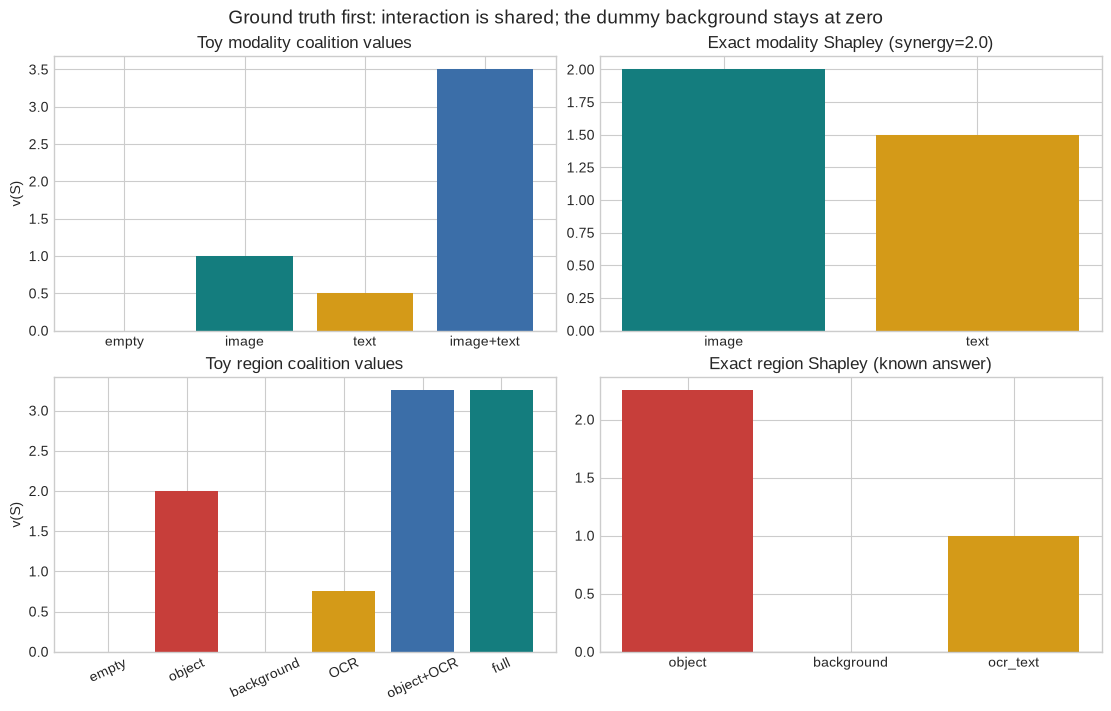

In [26]:
if MAIN:
    toy_modality = vlm_modality_shap_report()
if MAIN:
    toy_region = vlm_region_shap_report()
if MAIN:
    toy_modality_game_values = vlm_modality_game()
if MAIN:
    toy_region_game_values = vlm_region_game()
if MAIN:

    region_fig, region_axes = plt.subplots(2, 2, figsize=(11, 7), constrained_layout=True)
modality_labels = ["empty", "image", "text", "image+text"]
if MAIN:
    modality_scores = [
        toy_modality_game_values[frozenset()],
        toy_modality_game_values[frozenset({0})],
        toy_modality_game_values[frozenset({1})],
        toy_modality_game_values[frozenset({0, 1})],
    ]
if MAIN:
    region_axes[0, 0].bar(modality_labels, modality_scores, color=[COLORS["gray"], COLORS["teal"], COLORS["gold"], COLORS["blue"]])
if MAIN:
    region_axes[0, 0].set_title("Toy modality coalition values")
if MAIN:
    region_axes[0, 0].set_ylabel("v(S)")
if MAIN:
    region_axes[0, 1].bar(["image", "text"], toy_modality.modality_values.tolist(), color=[COLORS["teal"], COLORS["gold"]])
if MAIN:
    region_axes[0, 1].set_title(f"Exact modality Shapley (synergy={toy_modality.synergy:.1f})")

region_labels = ["empty", "object", "background", "OCR", "object+OCR", "full"]
if MAIN:
    region_keys = [frozenset(), frozenset({0}), frozenset({1}), frozenset({2}), frozenset({0, 2}), frozenset({0, 1, 2})]
if MAIN:
    region_axes[1, 0].bar(region_labels, [toy_region_game_values[key] for key in region_keys], color=[COLORS["gray"], COLORS["red"], COLORS["gray"], COLORS["gold"], COLORS["blue"], COLORS["teal"]])
if MAIN:
    region_axes[1, 0].tick_params(axis="x", rotation=25)
if MAIN:
    region_axes[1, 0].set_title("Toy region coalition values")
if MAIN:
    region_axes[1, 0].set_ylabel("v(S)")
if MAIN:
    region_axes[1, 1].bar(toy_region.region_names, toy_region.region_values.tolist(), color=[COLORS["red"], COLORS["gray"], COLORS["gold"]])
if MAIN:
    region_axes[1, 1].axhline(0, color=COLORS["ink"], linewidth=0.8)
if MAIN:
    region_axes[1, 1].set_title("Exact region Shapley (known answer)")
if MAIN:
    region_fig.suptitle("Ground truth first: interaction is shared; the dummy background stays at zero", fontsize=14)
if MAIN:
    toy_asset = assets_dir / "vlm_modality_region_toy_ground_truth.png"
if MAIN:
    region_fig.savefig(toy_asset, dpi=170, bbox_inches="tight")
if MAIN:
    plt.show()

<img src="../../exercises/part7_token_region_shap/media/vlm_modality_region_toy_ground_truth.png" alt="Toy modality and region ground truth" width="950">

<details>
<summary>Interpretation</summary>

The modality interaction of `2.0` is split equally, producing image/text values `[2.0, 1.5]`. In the
region game, the object/OCR interaction of `0.5` is also split, producing `[2.25, 0.0, 1.0]`. The
background receives exactly zero even though it appears in half the coalitions. This is the behavior
we expect before accepting any learned-model result.

</details>

## 4. Signature Result - score every rendered coalition with pinned CLIP

We now run `openai/clip-vit-base-patch32` at pinned revision
`3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268` on CUDA. There is **no CPU or synthetic-score fallback**.

The modality game uses counterfactual replacements, not literal absence:

- image player absent/present means **blue circle / red square**;
- text player absent/present means **neutral “a photo” / target “a red square”**.

The region game renders all eight combinations of object, gray background, and OCR text, always
scored against “a red square”. The target-vs-distractor control separately checks that the full
red-square image scores above “a blue circle”.

In [27]:
region_reference_MAIN = False
if region_reference_MAIN:
    # %%
    """Reference solutions for [16.5] VLM Modality and Region SHAP."""

import itertools
import math
import sys
from collections.abc import Callable, Mapping
from dataclasses import dataclass
from pathlib import Path

import torch as t

region_reference_chapter = "chapter16_shapley_attribution_baselines"
if region_reference_MAIN:
    region_reference_root_dir = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / region_reference_chapter).exists())
if region_reference_MAIN:
    if str(region_reference_root_dir) not in sys.path:
        sys.path.append(str(region_reference_root_dir))

region_reference_MAIN = False
Coalition = frozenset[int]

region_reference_REAL_CLIP_MODEL_ID = "openai/clip-vit-base-patch32"
region_reference_REAL_CLIP_REVISION = "3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268"
region_reference_REAL_CLIP_NEUTRAL_TEXT = "a photo"
region_reference_REAL_CLIP_TARGET_TEXT = "a red square"
region_reference_REAL_CLIP_DISTRACTOR_TEXT = "a blue circle"
region_reference_REAL_CLIP_MODALITY_SYNERGY_MIN = 2.0
region_reference_REAL_CLIP_REGION_MARGIN_MIN = 1.0
region_reference_REAL_CLIP_TARGET_DISTRACTOR_MARGIN_MIN = 2.0


@dataclass(frozen=True)
class region_reference_ShapleyEfficiencyReport:
    shapley_sum: float
    total_value_delta: float
    efficiency_error: float
    satisfies_efficiency: bool


@dataclass(frozen=True)
class region_reference_VLMModalitySHAPReport:
    modality_values: t.Tensor
    baseline_score: float
    image_only_score: float
    text_only_score: float
    full_score: float
    synergy: float
    detects_synergy: bool
    satisfies_efficiency: bool


@dataclass(frozen=True)
class region_reference_VLMRegionSHAPReport:
    region_values: t.Tensor
    region_names: tuple[str, ...]
    target_region: str
    target_value: float
    max_background_value: float
    localizes_target: bool
    satisfies_efficiency: bool


# %%
def region_reference_all_coalitions(num_players: int) -> tuple[Coalition, ...]:
    """Return every player subset for a finite cooperative game."""

    if num_players <= 0:
        raise ValueError("num_players must be positive.")
    players = range(num_players)
    coalitions: list[Coalition] = []
    for size in range(num_players + 1):
        coalitions.extend(frozenset(group) for group in itertools.combinations(players, size))
    return tuple(coalitions)


def region_reference_normalize_coalition_values(
    coalition_values: Mapping[Coalition | tuple[int, ...], float],
    *,
    num_players: int,
) -> dict[Coalition, float]:
    """Normalize coalition keys and require a complete value table."""

    values = {frozenset(key): float(value) for key, value in coalition_values.items()}
    expected = set(region_reference_all_coalitions(num_players))
    missing = expected - set(values)
    if missing:
        raise ValueError(f"coalition value table is missing {len(missing)} coalitions.")
    return values


def region_reference_coalition_values_from_function(
    num_players: int,
    value_fn: Callable[[Coalition], float],
) -> dict[Coalition, float]:
    """Evaluate `value_fn` on the complete coalition table."""

    return {coalition: float(value_fn(coalition)) for coalition in region_reference_all_coalitions(num_players)}


def region_reference_exact_shapley_values(
    coalition_values: Mapping[Coalition | tuple[int, ...], float],
    *,
    num_players: int,
) -> t.Tensor:
    """Compute exact Shapley values by summing weighted marginal effects."""

    values = region_reference_normalize_coalition_values(coalition_values, num_players=num_players)
    shapley = t.zeros(num_players, dtype=t.float64)
    denominator = math.factorial(num_players)
    for player in range(num_players):
        others = [candidate for candidate in range(num_players) if candidate != player]
        for size in range(num_players):
            weight = (
                math.factorial(size)
                * math.factorial(num_players - size - 1)
                / denominator
            )
            for group in itertools.combinations(others, size):
                coalition = frozenset(group)
                shapley[player] += weight * (values[coalition | {player}] - values[coalition])
    return shapley


def region_reference_shapley_efficiency_report(
    coalition_values: Mapping[Coalition | tuple[int, ...], float],
    *,
    num_players: int,
    tolerance: float = 1e-9,
) -> region_reference_ShapleyEfficiencyReport:
    """Check that Shapley values sum to `full_coalition - empty_coalition`."""

    values = region_reference_normalize_coalition_values(coalition_values, num_players=num_players)
    shapley = region_reference_exact_shapley_values(values, num_players=num_players)
    total_delta = values[frozenset(range(num_players))] - values[frozenset()]
    shapley_sum = float(shapley.sum().item())
    efficiency_error = abs(shapley_sum - total_delta)
    return region_reference_ShapleyEfficiencyReport(
        shapley_sum=shapley_sum,
        total_value_delta=total_delta,
        efficiency_error=efficiency_error,
        satisfies_efficiency=efficiency_error <= tolerance,
    )


def region_reference_vlm_modality_game(
    *,
    image_weight: float = 1.0,
    text_weight: float = 0.5,
    synergy_weight: float = 2.0,
) -> dict[Coalition, float]:
    """Return a two-player image/text game with multimodal synergy."""

    def value_fn(coalition: Coalition) -> float:
        image_present = 0 in coalition
        text_present = 1 in coalition
        score = 0.0
        if image_present:
            score += image_weight
        if text_present:
            score += text_weight
        if image_present and text_present:
            score += synergy_weight
        return score

    return region_reference_coalition_values_from_function(2, value_fn)


def region_reference_vlm_modality_shap_report(
    *,
    image_weight: float = 1.0,
    text_weight: float = 0.5,
    synergy_weight: float = 2.0,
    min_synergy: float = 1.0,
    tolerance: float = 1e-9,
) -> region_reference_VLMModalitySHAPReport:
    """Compute modality Shapley values and detect image/text synergy."""

    values = region_reference_vlm_modality_game(
        image_weight=image_weight,
        text_weight=text_weight,
        synergy_weight=synergy_weight,
    )
    modality_values = region_reference_exact_shapley_values(values, num_players=2)
    baseline = values[frozenset()]
    image_only = values[frozenset({0})]
    text_only = values[frozenset({1})]
    full = values[frozenset({0, 1})]
    synergy = full - image_only - text_only + baseline
    efficiency_error = abs(float(modality_values.sum().item()) - (full - baseline))
    return region_reference_VLMModalitySHAPReport(
        modality_values=modality_values,
        baseline_score=baseline,
        image_only_score=image_only,
        text_only_score=text_only,
        full_score=full,
        synergy=synergy,
        detects_synergy=synergy >= min_synergy,
        satisfies_efficiency=efficiency_error <= tolerance,
    )


def region_reference_vlm_region_game(
    *,
    object_weight: float = 2.0,
    ocr_weight: float = 0.75,
    object_ocr_interaction: float = 0.5,
) -> dict[Coalition, float]:
    """Return a three-player object/background/OCR region game."""

    def value_fn(coalition: Coalition) -> float:
        object_present = 0 in coalition
        ocr_present = 2 in coalition
        score = 0.0
        if object_present:
            score += object_weight
        if ocr_present:
            score += ocr_weight
        if object_present and ocr_present:
            score += object_ocr_interaction
        return score

    return region_reference_coalition_values_from_function(3, value_fn)


def region_reference_vlm_region_shap_report(
    *,
    region_names: tuple[str, ...] = ("object", "background", "ocr_text"),
    target_region: str = "object",
    min_margin: float = 0.5,
    tolerance: float = 1e-9,
) -> region_reference_VLMRegionSHAPReport:
    """Compute structured region Shapley values and check target localization."""

    if len(region_names) != 3:
        raise ValueError("region_names must name object, background, and OCR regions.")
    if target_region not in region_names:
        raise ValueError("target_region must be one of region_names.")

    values = region_reference_vlm_region_game()
    region_values = region_reference_exact_shapley_values(values, num_players=3)
    target_index = region_names.index(target_region)
    target_value = float(region_values[target_index].item())
    max_background = max(
        abs(float(value.item()))
        for index, value in enumerate(region_values)
        if index != target_index
    )
    efficiency = region_reference_shapley_efficiency_report(values, num_players=3, tolerance=tolerance)
    return region_reference_VLMRegionSHAPReport(
        region_values=region_values,
        region_names=region_names,
        target_region=target_region,
        target_value=target_value,
        max_background_value=max_background,
        localizes_target=target_value >= max_background + min_margin,
        satisfies_efficiency=efficiency.satisfies_efficiency,
    )


# %%
def region_reference__tensor_report(report) -> dict:
    result = report.__dict__.copy()
    for key, value in list(result.items()):
        if hasattr(value, "tolist"):
            result[key] = value.tolist()
    return result


def region_reference_modality_shap_smoke_test() -> dict:
    return region_reference__tensor_report(region_reference_vlm_modality_shap_report())


def region_reference_region_shap_smoke_test() -> dict:
    return region_reference__tensor_report(region_reference_vlm_region_shap_report())


def region_reference_run_smoke_test(cpu: bool = True) -> dict:
    _ = cpu
    return {
        "modality": region_reference_modality_shap_smoke_test(),
        "region": region_reference_region_shap_smoke_test(),
    }


def region_reference_run_gpu_test(max_vram_gb: float = 24.0) -> dict:
    if not t.cuda.is_available():
        raise RuntimeError("16.5 GPU preflight requires CUDA; no CPU fallback is accepted.")

    return region_reference_run_real_clip_vlm_shap_preflight(max_vram_gb=max_vram_gb)


def region_reference_render_shape_image(color: str, shape: str):
    """Render a deterministic 224x224 colored-shape image for CLIP preflights."""

    from PIL import Image, ImageDraw

    image = Image.new("RGB", (224, 224), "white")
    draw = ImageDraw.Draw(image)
    bbox = [55, 55, 169, 169]
    if shape == "square":
        draw.rectangle(bbox, fill=color)
    elif shape == "circle":
        draw.ellipse(bbox, fill=color)
    else:
        raise ValueError("shape must be 'square' or 'circle'.")
    return image


def region_reference_render_region_clip_image(
    *,
    object_present: bool,
    background_present: bool,
    ocr_present: bool,
):
    from PIL import Image, ImageDraw

    image = Image.new("RGB", (224, 224), (230, 230, 230) if background_present else "white")
    draw = ImageDraw.Draw(image)
    if object_present:
        draw.rectangle([55, 45, 169, 159], fill="red")
    if ocr_present:
        draw.text((88, 178), "RED", fill="black")
    return image


def region_reference__clip_scores(model, processor, *, images, texts, device: t.device) -> list[float]:
    inputs = processor(
        text=list(texts),
        images=list(images),
        return_tensors="pt",
        padding=True,
    ).to(device)
    with t.inference_mode():
        output = model(**inputs)
    logits = output.logits_per_image.detach().float()
    return [float(logits[index, index].item()) for index in range(len(images))]


def region_reference_run_real_clip_vlm_shap_preflight(
    max_vram_gb: float = 24.0,
    *,
    include_visuals: bool = False,
) -> dict:
    from huggingface_hub import snapshot_download
    from transformers import CLIPModel, CLIPProcessor

    device = t.device("cuda")
    t.cuda.reset_peak_memory_stats()
    local_snapshot = snapshot_download(
        region_reference_REAL_CLIP_MODEL_ID,
        revision=region_reference_REAL_CLIP_REVISION,
        allow_patterns=[
            "config.json",
            "preprocessor_config.json",
            "tokenizer.json",
            "tokenizer_config.json",
            "special_tokens_map.json",
            "vocab.json",
            "merges.txt",
            "pytorch_model.bin",
        ],
    )
    processor = CLIPProcessor.from_pretrained(local_snapshot, backend="pil")
    model = CLIPModel.from_pretrained(local_snapshot, use_safetensors=False).to(device)
    model.eval()

    target_image = region_reference_render_shape_image("red", "square")
    distractor_image = region_reference_render_shape_image("blue", "circle")
    modality_coalitions = [frozenset(), frozenset({0}), frozenset({1}), frozenset({0, 1})]
    modality_images = [
        target_image if 0 in coalition else distractor_image
        for coalition in modality_coalitions
    ]
    modality_texts = [
        region_reference_REAL_CLIP_TARGET_TEXT if 1 in coalition else region_reference_REAL_CLIP_NEUTRAL_TEXT
        for coalition in modality_coalitions
    ]
    modality_raw_scores = region_reference__clip_scores(
        model,
        processor,
        images=modality_images,
        texts=modality_texts,
        device=device,
    )
    modality_table = {
        coalition: score for coalition, score in zip(modality_coalitions, modality_raw_scores)
    }
    modality_values = region_reference_exact_shapley_values(modality_table, num_players=2)
    modality_synergy = (
        modality_table[frozenset({0, 1})]
        - modality_table[frozenset({0})]
        - modality_table[frozenset({1})]
        + modality_table[frozenset()]
    )
    modality_efficiency = region_reference_shapley_efficiency_report(modality_table, num_players=2)

    region_coalitions = [
        frozenset(group)
        for size in range(4)
        for group in itertools.combinations(range(3), size)
    ]
    region_images = [
        region_reference_render_region_clip_image(
            object_present=0 in coalition,
            background_present=1 in coalition,
            ocr_present=2 in coalition,
        )
        for coalition in region_coalitions
    ]
    region_scores = region_reference__clip_scores(
        model,
        processor,
        images=region_images,
        texts=[region_reference_REAL_CLIP_TARGET_TEXT] * len(region_images),
        device=device,
    )
    region_table = {
        coalition: score for coalition, score in zip(region_coalitions, region_scores)
    }
    region_values = region_reference_exact_shapley_values(region_table, num_players=3)
    object_value = float(region_values[0].item())
    max_non_object = max(abs(float(value.item())) for value in region_values[1:])
    object_margin = object_value - max_non_object
    region_efficiency = region_reference_shapley_efficiency_report(region_table, num_players=3)

    target_and_distractor_scores = region_reference__clip_scores(
        model,
        processor,
        images=[target_image, target_image],
        texts=[region_reference_REAL_CLIP_TARGET_TEXT, region_reference_REAL_CLIP_DISTRACTOR_TEXT],
        device=device,
    )
    target_distractor_margin = target_and_distractor_scores[0] - target_and_distractor_scores[1]

    t.cuda.synchronize()
    peak_vram_gb = t.cuda.max_memory_allocated() / 1024**3
    preflight_passed = (
        modality_synergy >= region_reference_REAL_CLIP_MODALITY_SYNERGY_MIN
        and modality_efficiency.satisfies_efficiency
        and object_margin >= region_reference_REAL_CLIP_REGION_MARGIN_MIN
        and region_efficiency.satisfies_efficiency
        and target_distractor_margin >= region_reference_REAL_CLIP_TARGET_DISTRACTOR_MARGIN_MIN
        and peak_vram_gb <= max_vram_gb
    )

    visual_payload = None
    if include_visuals:
        visual_payload = {
            "target_image": target_image,
            "distractor_image": distractor_image,
            "target_text": region_reference_REAL_CLIP_TARGET_TEXT,
            "distractor_text": region_reference_REAL_CLIP_DISTRACTOR_TEXT,
            "neutral_text": region_reference_REAL_CLIP_NEUTRAL_TEXT,
            "modality_coalitions": modality_coalitions,
            "modality_images": modality_images,
            "modality_texts": modality_texts,
            "modality_scores": modality_raw_scores,
            "region_coalitions": region_coalitions,
            "region_images": region_images,
            "region_scores": region_scores,
            "target_and_distractor_scores": target_and_distractor_scores,
        }

    del model, processor
    t.cuda.empty_cache()

    result = {
        "preflight_passed": preflight_passed,
        "cuda_available": True,
        "device": t.cuda.get_device_name(0),
        "model_id": region_reference_REAL_CLIP_MODEL_ID,
        "revision": region_reference_REAL_CLIP_REVISION,
        "local_snapshot": str(local_snapshot),
        "claim_scope": "pinned_real_clip_rendered_vlm_shap_preflight",
        "modality_players": ["image", "text"],
        "modality_values": modality_values.tolist(),
        "modality_synergy": modality_synergy,
        "modality_satisfies_efficiency": modality_efficiency.satisfies_efficiency,
        "modality_scores": {str(sorted(coalition)): score for coalition, score in modality_table.items()},
        "region_names": ["object", "background", "ocr_text"],
        "region_values": region_values.tolist(),
        "object_value": object_value,
        "max_non_object_value": max_non_object,
        "object_margin": object_margin,
        "region_satisfies_efficiency": region_efficiency.satisfies_efficiency,
        "target_distractor_margin": target_distractor_margin,
        "peak_vram_gb": peak_vram_gb,
        "within_vram_budget": peak_vram_gb <= max_vram_gb,
        "full_path": "Run modality and region SHAP on a pinned CLIP checkpoint with deterministic rendered image/text coalitions.",
    }
    if visual_payload is not None:
        result["visual_payload"] = visual_payload
    return result


def region_reference_run_real_clip_vlm_shap_signature_result(max_vram_gb: float = 24.0) -> dict:
    """Run the pinned CLIP experiment and retain every learner-facing coalition."""

    return region_reference_run_real_clip_vlm_shap_preflight(
        max_vram_gb=max_vram_gb,
        include_visuals=True,
    )


def region_reference_run_full_experiment(max_vram_gb: float = 24.0) -> dict:
    """Run the validated experiment path used by the verification report."""

    return region_reference_run_gpu_test(max_vram_gb=max_vram_gb)


if region_reference_MAIN:
    print(region_reference_run_smoke_test())

In [28]:
region_reference = SimpleNamespace(
    ShapleyEfficiencyReport=region_reference_ShapleyEfficiencyReport,
    VLMModalitySHAPReport=region_reference_VLMModalitySHAPReport,
    VLMRegionSHAPReport=region_reference_VLMRegionSHAPReport,
    all_coalitions=region_reference_all_coalitions,
    normalize_coalition_values=region_reference_normalize_coalition_values,
    coalition_values_from_function=region_reference_coalition_values_from_function,
    exact_shapley_values=region_reference_exact_shapley_values,
    shapley_efficiency_report=region_reference_shapley_efficiency_report,
    vlm_modality_game=region_reference_vlm_modality_game,
    vlm_modality_shap_report=region_reference_vlm_modality_shap_report,
    vlm_region_game=region_reference_vlm_region_game,
    vlm_region_shap_report=region_reference_vlm_region_shap_report,
    _tensor_report=region_reference__tensor_report,
    modality_shap_smoke_test=region_reference_modality_shap_smoke_test,
    region_shap_smoke_test=region_reference_region_shap_smoke_test,
    run_smoke_test=region_reference_run_smoke_test,
    run_gpu_test=region_reference_run_gpu_test,
    render_shape_image=region_reference_render_shape_image,
    render_region_clip_image=region_reference_render_region_clip_image,
    _clip_scores=region_reference__clip_scores,
    run_real_clip_vlm_shap_preflight=region_reference_run_real_clip_vlm_shap_preflight,
    run_real_clip_vlm_shap_signature_result=region_reference_run_real_clip_vlm_shap_signature_result,
    run_full_experiment=region_reference_run_full_experiment,
)

In [29]:
if MAIN:
    signature_result = region_reference.run_real_clip_vlm_shap_signature_result(max_vram_gb=24.0)
if MAIN:
    region_tests.validate_real_clip_vlm_shap_visual_payload(signature_result)
if MAIN:
    payload = signature_result["visual_payload"]
if MAIN:

    print(f"device: {signature_result['device']}")
if MAIN:
    print(f"model: {signature_result['model_id']} @ {signature_result['revision'][:10]}...")
if MAIN:
    print(f"peak VRAM: {signature_result['peak_vram_gb']:.3f} GB")

/home/bitwise/Documents/ARENA_3.0_Extended/.claude/worktrees/env-upgrade-54fd7e/.venv/lib/python3.14/site-packages/torchao/quantization/quant_api.py:1558: SyntaxWarning: "\." is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\."? A raw string is also an option.
  * regex for parameter names, must start with `re:`, e.g. `re:language\.layers\..+\.q_proj.weight`.


All tests in `validate_real_clip_vlm_shap_visual_payload` passed!
device: NVIDIA GeForce RTX 5090 Laptop GPU
model: openai/clip-vit-base-patch32 @ 3d74acf9a2...
peak VRAM: 0.601 GB


In [30]:
def coalition_label(coalition: Coalition, names: tuple[str, ...]) -> str:
    return "+".join(names[index] for index in sorted(coalition)) or "empty"
if MAIN:


    region_rows = [
        {
            "coalition": coalition_label(coalition, ("object", "background", "OCR")),
            "object": 0 in coalition,
            "background": 1 in coalition,
            "OCR": 2 in coalition,
            "CLIP target score": score,
        }
        for coalition, score in zip(
            payload["region_coalitions"], payload["region_scores"]
        )
    ]
if MAIN:
    display(pd.DataFrame(region_rows).round(3))

,coalition,object,background,OCR,CLIP target score
0,empty,False,False,False,20.705
1,object,True,False,False,29.093
2,background,False,True,False,19.836
3,OCR,False,False,True,27.234
4,object+background,True,True,False,28.325
5,object+OCR,True,False,True,30.204
6,background+OCR,False,True,True,27.423
7,object+background+OCR,True,True,True,30.125


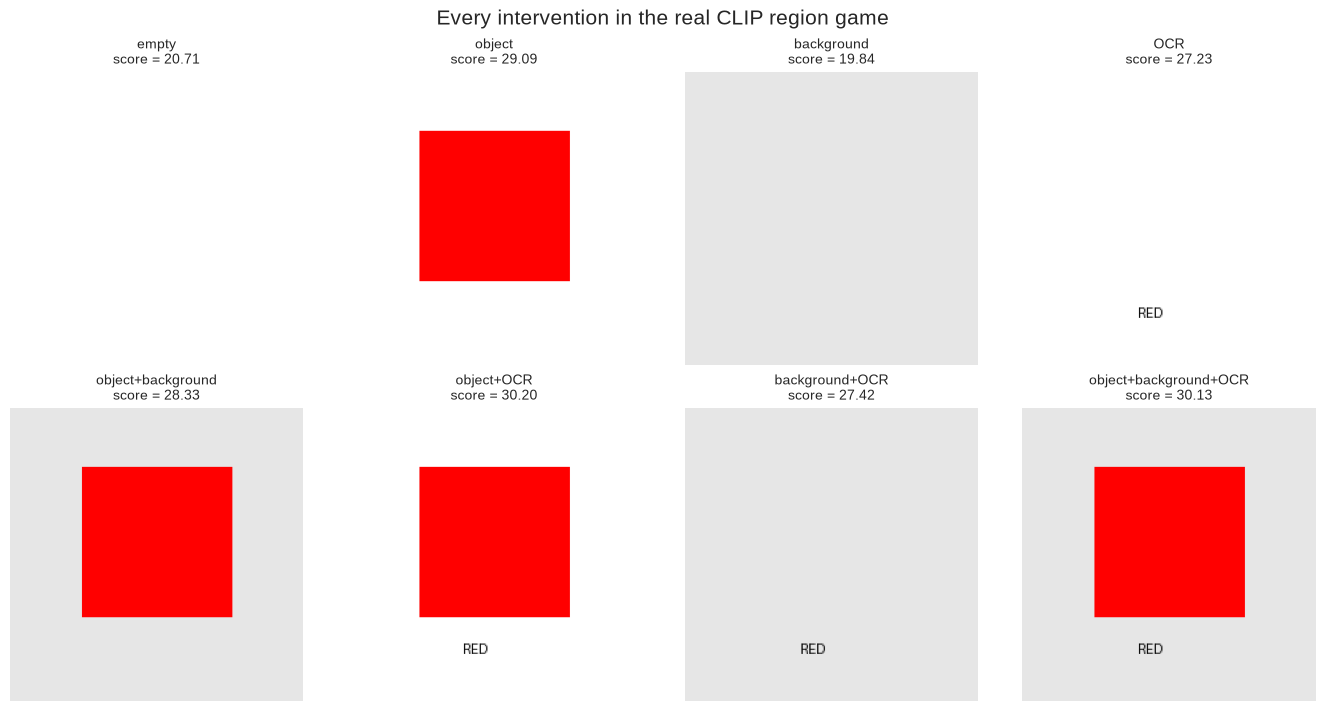

In [31]:
if MAIN:
    region_fig, region_axes = plt.subplots(2, 4, figsize=(13.5, 7), constrained_layout=True)
if MAIN:
    for ax, coalition, image, score in zip(
        region_axes.flat,
        payload["region_coalitions"],
        payload["region_images"],
        payload["region_scores"],
    ):
        ax.imshow(image)
        ax.set_title(
            f"{coalition_label(coalition, ('object', 'background', 'OCR'))}\nscore = {score:.2f}",
            fontsize=10,
        )
        ax.axis("off")
if MAIN:
    region_fig.suptitle("Every intervention in the real CLIP region game", fontsize=15)
if MAIN:
    coalition_asset = assets_dir / "vlm_region_clip_coalitions.png"
if MAIN:
    region_fig.savefig(coalition_asset, dpi=180, bbox_inches="tight")
if MAIN:
    plt.show()

<img src="../../exercises/part7_token_region_shap/media/vlm_region_clip_coalitions.png" alt="All eight rendered CLIP coalitions" width="950">

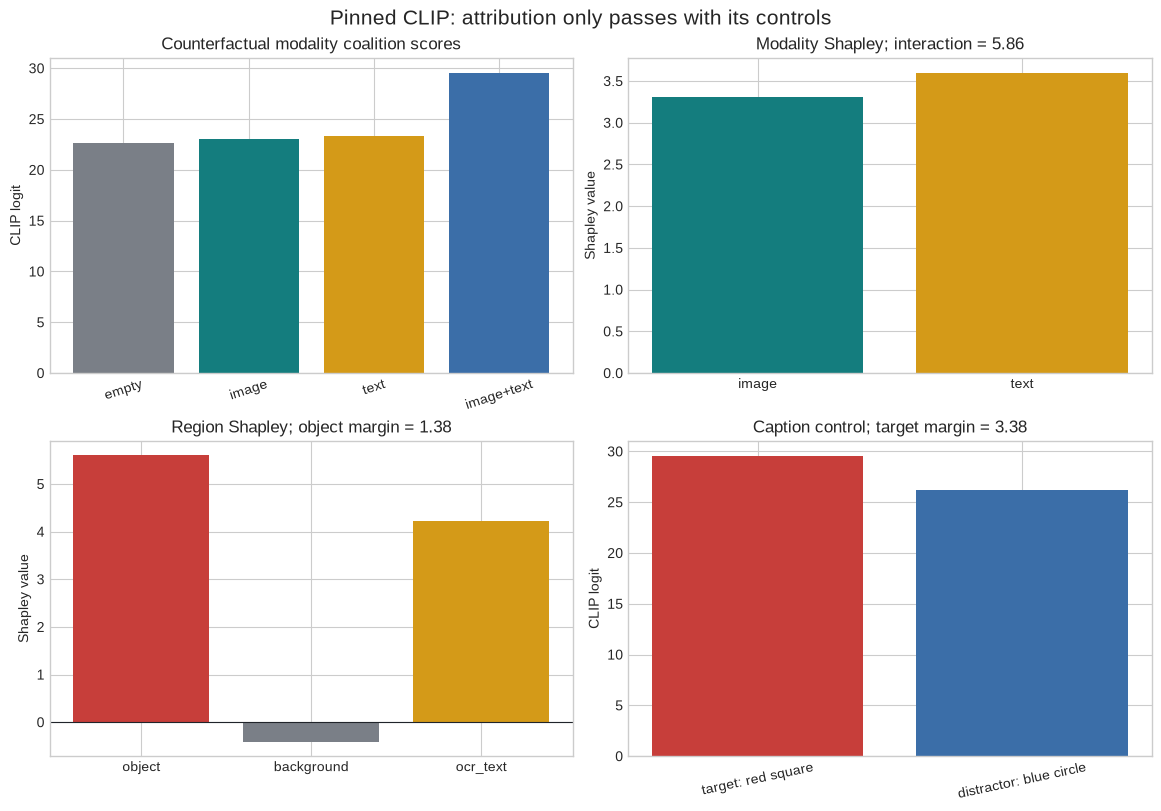

In [32]:
if MAIN:
    modality_labels = [
        coalition_label(coalition, ("image", "text"))
        for coalition in payload["modality_coalitions"]
    ]
if MAIN:
    target_score, distractor_score = payload["target_and_distractor_scores"]
if MAIN:

    region_fig, region_axes = plt.subplots(2, 2, figsize=(11.5, 8), constrained_layout=True)
if MAIN:
    region_axes[0, 0].bar(modality_labels, payload["modality_scores"], color=[COLORS["gray"], COLORS["teal"], COLORS["gold"], COLORS["blue"]])
if MAIN:
    region_axes[0, 0].set_title("Counterfactual modality coalition scores")
if MAIN:
    region_axes[0, 0].set_ylabel("CLIP logit")
if MAIN:
    region_axes[0, 0].tick_params(axis="x", rotation=18)
if MAIN:

    region_axes[0, 1].bar(["image", "text"], signature_result["modality_values"], color=[COLORS["teal"], COLORS["gold"]])
if MAIN:
    region_axes[0, 1].set_title(f"Modality Shapley; interaction = {signature_result['modality_synergy']:.2f}")
if MAIN:
    region_axes[0, 1].set_ylabel("Shapley value")
if MAIN:

    region_axes[1, 0].bar(signature_result["region_names"], signature_result["region_values"], color=[COLORS["red"], COLORS["gray"], COLORS["gold"]])
if MAIN:
    region_axes[1, 0].axhline(0, color=COLORS["ink"], linewidth=0.8)
if MAIN:
    region_axes[1, 0].set_title(f"Region Shapley; object margin = {signature_result['object_margin']:.2f}")
if MAIN:
    region_axes[1, 0].set_ylabel("Shapley value")
if MAIN:

    region_axes[1, 1].bar(["target: red square", "distractor: blue circle"], [target_score, distractor_score], color=[COLORS["red"], COLORS["blue"]])
if MAIN:
    region_axes[1, 1].set_title(f"Caption control; target margin = {signature_result['target_distractor_margin']:.2f}")
if MAIN:
    region_axes[1, 1].set_ylabel("CLIP logit")
if MAIN:
    region_axes[1, 1].tick_params(axis="x", rotation=12)
if MAIN:

    region_fig.suptitle("Pinned CLIP: attribution only passes with its controls", fontsize=15)
if MAIN:
    signature_asset = assets_dir / "vlm_modality_region_live_signature.png"
if MAIN:
    region_fig.savefig(signature_asset, dpi=180, bbox_inches="tight")
if MAIN:
    plt.show()

<img src="../../exercises/part7_token_region_shap/media/vlm_modality_region_live_signature.png" alt="Pinned CLIP modality and region SHAP signature result" width="950">

<details open>
<summary>What the result says</summary>

On the pinned run, the modality coalition scores are approximately `22.65`, `23.03`, `23.32`, and
`29.56`. Their interaction contrast is about `5.86`, while exact Shapley assigns about `3.31` to the
image replacement and `3.60` to the text replacement. In the region game, object/background/OCR
values are approximately `5.61`, `-0.41`, and `4.23`; the object wins by about `1.38`. The full
red-square image also scores its target caption above the blue-circle distractor by about `3.38`.

The result therefore supports the narrow claim: **for this finite rendered game and pinned score,
the target object has the largest region attribution, the background control does not explain the
result, and image/text evidence interacts positively.**

</details>

<details>
<summary>Why the negative background value is not a bug</summary>

Replacing white with gray slightly lowers the target score on average, so its Shapley value is
negative. We compare the object against the **absolute** non-object attribution when applying the
localization margin; a strong suppressive confound should not be ignored merely because its sign is
negative.

</details>

## Try It Yourself

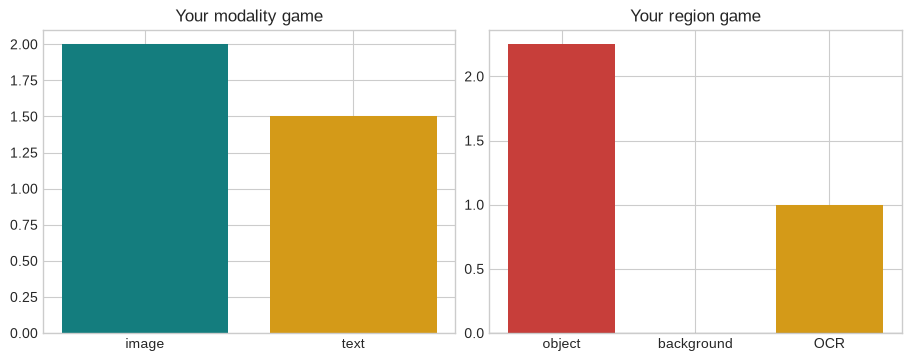

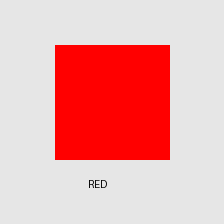

object+background+OCR CLIP target score=30.125


In [33]:
# Change these values, rerun the cell, and predict which control fails first.
PLAY_IMAGE_WEIGHT = 1.0
PLAY_TEXT_WEIGHT = 0.5
PLAY_SYNERGY = 2.0
PLAY_OBJECT_WEIGHT = 2.0
PLAY_OCR_WEIGHT = 0.75
PLAY_OBJECT_OCR_INTERACTION = 0.5
PLAY_COALITION_INDEX = 7  # 0..7, indexes the real rendered coalitions above
if MAIN:

    play_modality_values = vlm_modality_game(
        image_weight=PLAY_IMAGE_WEIGHT,
        text_weight=PLAY_TEXT_WEIGHT,
        synergy_weight=PLAY_SYNERGY,
    )
if MAIN:
    play_modality_shap = region_exact_shapley_values(play_modality_values, num_players=2)
if MAIN:
    play_region_values = vlm_region_game(
        object_weight=PLAY_OBJECT_WEIGHT,
        ocr_weight=PLAY_OCR_WEIGHT,
        object_ocr_interaction=PLAY_OBJECT_OCR_INTERACTION,
    )
if MAIN:
    play_region_shap = region_exact_shapley_values(play_region_values, num_players=3)
if MAIN:

    region_fig, region_axes = plt.subplots(1, 2, figsize=(9, 3.5), constrained_layout=True)
if MAIN:
    region_axes[0].bar(["image", "text"], play_modality_shap.tolist(), color=[COLORS["teal"], COLORS["gold"]])
if MAIN:
    region_axes[0].set_title("Your modality game")
if MAIN:
    region_axes[1].bar(["object", "background", "OCR"], play_region_shap.tolist(), color=[COLORS["red"], COLORS["gray"], COLORS["gold"]])
if MAIN:
    region_axes[1].axhline(0, color=COLORS["ink"], linewidth=0.8)
if MAIN:
    region_axes[1].set_title("Your region game")
if MAIN:
    plt.show()
if MAIN:

    chosen = PLAY_COALITION_INDEX % len(payload["region_images"])
if MAIN:
    display(payload["region_images"][chosen])
if MAIN:
    print(
        coalition_label(payload["region_coalitions"][chosen], ("object", "background", "OCR")),
        f"CLIP target score={payload['region_scores'][chosen]:.3f}",
    )

<details>
<summary>Experiments worth trying</summary>

1. Set `PLAY_SYNERGY = 0`. The Shapley values should become purely additive.
2. Increase `PLAY_OCR_WEIGHT` beyond the object weight. The localization claim should fail even though efficiency still passes.
3. Make `PLAY_OBJECT_OCR_INTERACTION` negative. Check how shared suppressive credit is divided.
4. Step through all eight real coalitions and ask whether the numeric ordering matches what you would have guessed from the images alone.

</details>

## Bonus: Hunt an Anomaly

The object wins this game, but OCR still receives a large positive value. Design a new
*pre-registered* intervention family that can distinguish color evidence from shape evidence and
genuine object evidence from typography. Before running CLIP, write down:

- the new players and exact render operation for each;
- which coalition is the negative control;
- the minimum margin that would count as a positive result;
- one outcome that would make you reject your preferred story.

Good anomaly targets include changing `RED` to a conflicting color word, moving text inside the
object, varying font size, swapping gray for textured backgrounds, and holding color fixed while
changing only shape. Run every coalition, not just the examples that look persuasive.

## Limitations and Claim Boundary

**Supported:** exact Shapley is correct on finite games with known answers; the pinned CLIP
checkpoint passes efficiency, image/text interaction, object-vs-non-object, and target-vs-distractor
controls on this deterministic rendered family.

**Not supported:** these values are not a segmentation map, do not identify internal visual tokens
or circuits, do not establish causal mediation inside CLIP, and do not generalize to natural images
or generative VLM answers. “Absent” modalities are explicit counterfactual replacements, so a
different baseline defines a different game.

A next mechanistic step is to patch visual-token or residual activations for the same controlled
pairs and compare input-level Shapley with an internal causal metric. Section 16.8 makes that
comparison explicit.

## Reading

- Lundberg & Lee, [A Unified Approach to Interpreting Model Predictions](https://arxiv.org/abs/1705.07874)
- Radford et al., [Learning Transferable Visual Models From Natural Language Supervision](https://arxiv.org/abs/2103.00020)
- Castro, Gómez & Tejada, [Polynomial calculation of the Shapley value based on sampling](https://doi.org/10.1016/j.cor.2008.04.004)

## Verification Appendix

In [34]:
def _tensor_report(report) -> dict:
    result = report.__dict__.copy()
    for key, value in list(result.items()):
        if hasattr(value, "tolist"):
            result[key] = value.tolist()
    return result


def run_smoke_test(cpu: bool = True) -> dict:
    _ = cpu
    return {
        "modality": _tensor_report(vlm_modality_shap_report()),
        "region": _tensor_report(vlm_region_shap_report()),
    }


def region_run_gpu_test(max_vram_gb: float = 24.0) -> dict:
    return region_reference.run_real_clip_vlm_shap_preflight(max_vram_gb=max_vram_gb)


def region_run_full_experiment(max_vram_gb: float = 24.0) -> dict:
    return region_run_gpu_test(max_vram_gb=max_vram_gb)


if MAIN:
    region_tests.test_notebook_contract(run_smoke_test)

All tests in `test_notebook_contract` passed!


The committed `verification_report.json` records the same pinned CUDA run for automated regression
checks. It is supporting evidence; the images, coalition table, controls, and interpretation above
are the lesson.

# Bonus

## Finish the comparison

State the players, exact replacement intervention, utility units and empty-coalition baseline for
each explanation. Describe why credit can change with token grouping or unobserved correlated
coalitions, and why a pinned rendered-image result does not identify a VLM's internal mechanism.
Keep both play cells and anomaly hunts as exploratory changes to try.